# Imports

## Import the folder for compatibility (if running local)

In [1]:
import os
import sys

project_root = "Incremental-Learning-MycroftMinds"
cwd = os.path.abspath(os.getcwd())
while True:
    if os.path.basename(cwd) == project_root:
        if cwd not in sys.path:
            sys.path.insert(0, cwd)
        break
    parent = os.path.dirname(cwd)
    if parent == cwd:
        raise FileNotFoundError(f"Project root '{project_root}' not found in any parent directory.")
    cwd = parent

## Import external libs and internal models

In [2]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm

from src.data.io import load_dataset
from src.utils.memory import calculate_memory_usage
from src.utils.utils import get_device_data
from src.evaluation.metrics import calculate_metrics, all_time_aggregation_metrics
from src.evaluation.visualization import plot_part_predictions, plot_hourly_predictions, plot_date_range
from src.evaluation.training import all_valid_splits_seq_fit_predict, test_set_seq_fit_predict

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from river.forest import ARFRegressor
from river.tree import HoeffdingTreeRegressor
from src.evaluation.baseline import PreviousValueRegressor, SeasonalMeanRegressor
from src.trees import fastodt
from src.bagging import ARFRegressorFODT
from src.boosting import IncubationBoost
from src.ensemble_methods import elasticGBDT

import ipywidgets as widgets
widgets.IntSlider()

IntSlider(value=0)

# Download the splitted data

In [3]:
# check you data dir and file prefixes
data_dir = '../../data/second_batch/commercial'

## Evaluation Settings

In [4]:
DATA_FREQUENCY = 'H'  # Hour frequency
FORECAST_HORIZON = '1h'
SPIKE_PROMINENCE = 2.0  # For commercial data

In [5]:
# Measure loading time
start_time = time.time()

# Load data
train, valid, test = load_dataset(data_dir=data_dir, prefix='sb_com_hour_wfv', use_numpy=True)
FEATURES = ['time', 'device_id', 'hour', 'weekday', 'month', 
           'consumption_lag_1h', 'consumption_lag_2h', 'consumption_lag_3h', 'consumption_lag_24h']

loading_time = time.time() - start_time
print(f"Data loaded in {loading_time/60:.2f} minutes")

[INFO] Loading train data...
[INFO] Train data loaded: 2 samples
[INFO] Loading valid data...
[INFO] Valid data loaded: 2 samples
[INFO] Loading test data...
[INFO] Test data loaded: 2 samples
Data loaded in 0.00 minutes


## Data structure information

The data structure is as follows:
- For walk-forward validation:
  - `train` is a list of tuples, where each tuple is (X, y) for one split
  - `valid` is a list of tuples, where each tuple is (X, y) for one split
  - `test` is a tuple of (X, y)
- Each X array contains:
  - Column 0: `time` (`pandas.Timedelta`)
  - Column 1: `device_id` (`str`)
  - Other columns: time-related features and lag features

The memory usage of the loaded data is printed below:

In [6]:
train[0][0]

array([[Timestamp('2024-06-07 00:00:00+0200', tz='Europe/Prague'),
        'sub1', 22.0, ..., 0.625, 0.6275000000000546, 0.621818181818195],
       [Timestamp('2024-06-07 00:00:00+0200', tz='Europe/Prague'),
        'sub3', 22.0, ..., 0.31666666666660603, 0.32416666666669397,
        0.3072727272727372],
       [Timestamp('2024-06-07 00:00:00+0200', tz='Europe/Prague'),
        'sub2', 22.0, ..., 0.004166666666662877, 0.0033333333333303017,
        0.003636363636370664],
       ...,
       [Timestamp('2024-07-04 23:00:00+0200', tz='Europe/Prague'),
        'sub2', 21.0, ..., 0.004166666666662877, 0.004166666666662877,
        0.0033333333333397754],
       [Timestamp('2024-07-04 23:00:00+0200', tz='Europe/Prague'),
        'sub1', 21.0, ..., 0.5883333333334425, 0.6208333333330908,
        0.6091666666667758],
       [Timestamp('2024-07-04 23:00:00+0200', tz='Europe/Prague'),
        'sub3', 21.0, ..., 0.3674999999999879, 0.37333333333344854,
        0.3758333333333515]], shape=(2016, 9

In [7]:
# Print data structure and memory usage information
if isinstance(train, list):
    print(f"Training data: {len(train)} splits")
    print(f"Validation data: {len(valid)} splits")
    
    # Show first split shape
    print(f"First train split shape: X={train[0][0].shape}, y={train[0][1].shape}")
    print(f"First valid split shape: X={valid[0][0].shape}, y={valid[0][1].shape}")
    
    # Memory usage
    train_mem = sum(calculate_memory_usage(ts) for ts in train)
    valid_mem = sum(calculate_memory_usage(vs) for vs in valid)
    test_mem = calculate_memory_usage(test)
    
    print(f"\nMemory usage:")
    print(f"Train: {train_mem:.2f} MB")
    print(f"Valid: {valid_mem:.2f} MB")
    print(f"Test: {test_mem:.2f} MB")
    print(f"Total: {train_mem + valid_mem + test_mem:.2f} MB")
else:
    # For non-list structure
    print(f"Training data shape: X={train[0].shape}, y={train[1].shape}")
    print(f"Validation data shape: X={valid[0].shape}, y={valid[1].shape}")
    print(f"Test data shape: X={test[0].shape}, y={test[1].shape}")

Training data: 2 splits
Validation data: 2 splits
First train split shape: X=(2016, 9), y=(2016,)
First valid split shape: X=(2016, 9), y=(2016,)

Memory usage:
Train: 0.46 MB
Valid: 0.21 MB
Test: 0.09 MB
Total: 0.77 MB


# WFV Model Evaluation
(train+valid WFV)
- (1) `train[0]` vs `valid[0]`
- (2) `train[1]` vs `valid[1]`
- ...
- (n) `train[n]` vs `valid[n]`

, where: 
$$ train[1] = train[0]+valid[0] $$
$$...$$
$$ train[n] = train[0]+valid[0]+valid[1]+...+valid[n-1] $$

### Baseline model (seasonal averages)

In [8]:
update_freq = "14D"
bl_mean = SeasonalMeanRegressor
bl_mean_params = {}

In [9]:
bl_mean_train_period_predictions, bl_mean_valid_period_predictions,\
bl_mean_train_period_metrics, bl_mean_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=bl_mean,
    model_params=bl_mean_params,
    train=train,
    valid=valid,
    incremental=False,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    verbose=True
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]


Retraining model on data from 2024-06-07 00:00:00+02:00 to 2024-07-04 23:00:00+02:00

Time: 0.00 seconds
Predicting for chunk from 2024-07-05 00:00:00+02:00 to 2024-07-19 00:00:00+02:00

-------------------------

Retraining model on data from 2024-06-07 00:00:00+02:00 to 2024-07-19 00:00:00+02:00

Time: 0.00 seconds
Predicting for chunk from 2024-07-19 01:00:00+02:00 to 2024-08-01 23:00:00+02:00

-------------------------
Model's memory usage: 0.024620 MB
Metrics for Device: sub3 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0426
	MAE: 0.0368
	MAPE: 8.6680%

Directional Metrics:
	Directional Accuracy: 64.5306%
	First-Diff Correlation: 0.4312

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1667
		Recall: 0.1667
		F1: 0.1667
	Drops:
		Precision: 0.1304
		Recall: 0.1200
		F1: 0.1250

Delayed Detection (delta=1 

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]


Retraining model on data from 2024-06-07 00:00:00+02:00 to 2024-08-01 23:00:00+02:00

Time: 0.00 seconds
Predicting for chunk from 2024-08-02 00:00:00+02:00 to 2024-08-12 14:00:00+02:00

-------------------------
Model's memory usage: 0.024445 MB
Metrics for Device: sub3 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0454
	MAE: 0.0416
	MAPE: 9.5009%

Directional Metrics:
	Directional Accuracy: 59.4488%
	First-Diff Correlation: 0.5325

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.2500
		Recall: 0.3333
		F1: 0.2857
	Drops:
		Precision: 0.3750
		Recall: 0.4286
		F1: 0.4000
--------------------------------------------------

#### Results

In [10]:
print("\n\nValid period metrics:")
bl_mean_all_time_valid_metrics = all_time_aggregation_metrics(bl_mean_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: sub3
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0440 ± 0.0014
	MAE: 0.0392 ± 0.0024
	MAPE: 9.0845% ± 0.4164%

	Directional Metrics:
		Directional Accuracy: 61.9897% ± 2.5409%
		First-Diff Correlation: 0.4818 ± 0.0507

	Immediate Detection (delta=0):
		Spike Precision: 0.0833 ± 0.0833
		Spike Recall: 0.0833 ± 0.0833
		Spike F1: 0.0833 ± 0.0833
		Drop Precision: 0.0652 ± 0.0652
		Drop Recall: 0.0600 ± 0.0600
		Drop F1: 0.0625 ± 0.0625

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3333 ± 0.0833
		Spike Recall: 0.3750 ± 0.0417
		Spike F1: 0.3512 ± 0.0655
		Drop Precision: 0.3397 ± 0.0353
		Drop Recall: 0.3543 ± 0.0743
		Drop F1: 0.3458 ± 0.0542
Daily Metrics:
	RMSE: 0.9795 ± 0.0283
	MAE: 0.9176 ± 0.0476
	MAPE: 9.1029% ± 0.4692%

	Directional Metrics:
		Directional Accuracy: 50.9259% ± 0.9259%
		First-Diff Correlation: 0.7495 ± 0.1897

	Immediate Detection (delta=0):
		Spike 

#### Validation plots

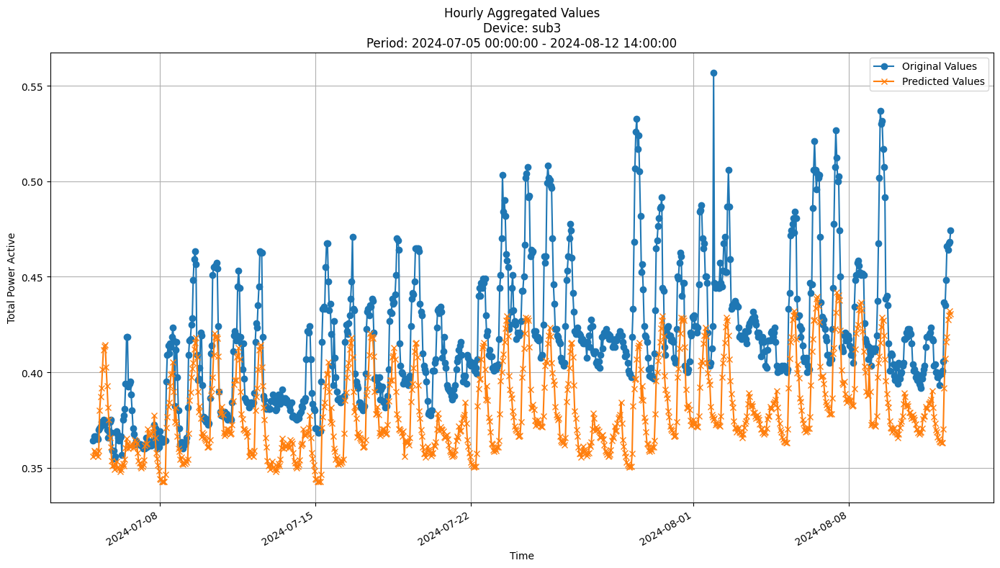


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0434
MAE: 0.0381
MAPE: 8.8971%

Directional Metrics:
Directional Accuracy: 63.1749%
First-Diff Correlation: 0.4562

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


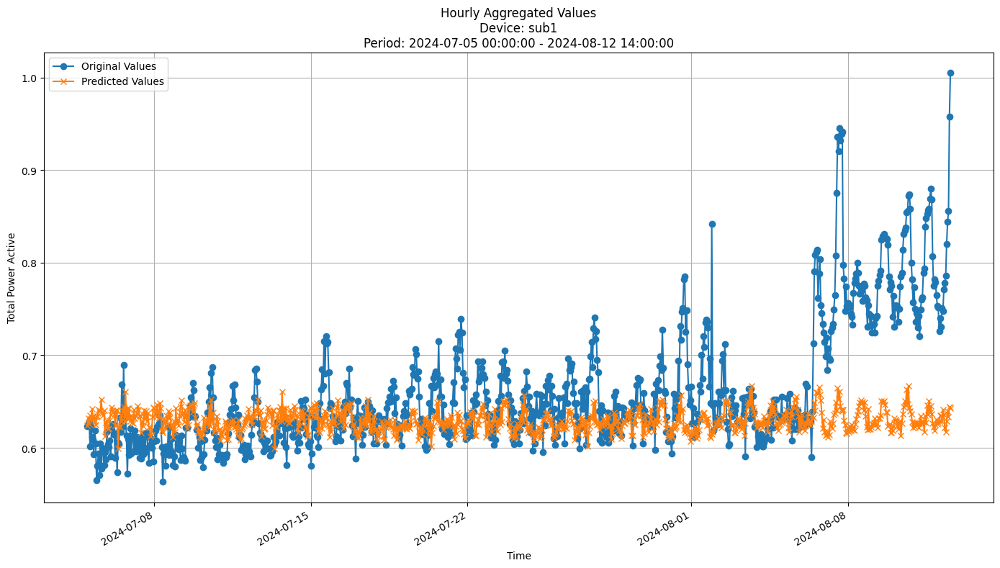


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0717
MAE: 0.0458
MAPE: 6.3439%

Directional Metrics:
Directional Accuracy: 53.8877%
First-Diff Correlation: 0.1047

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


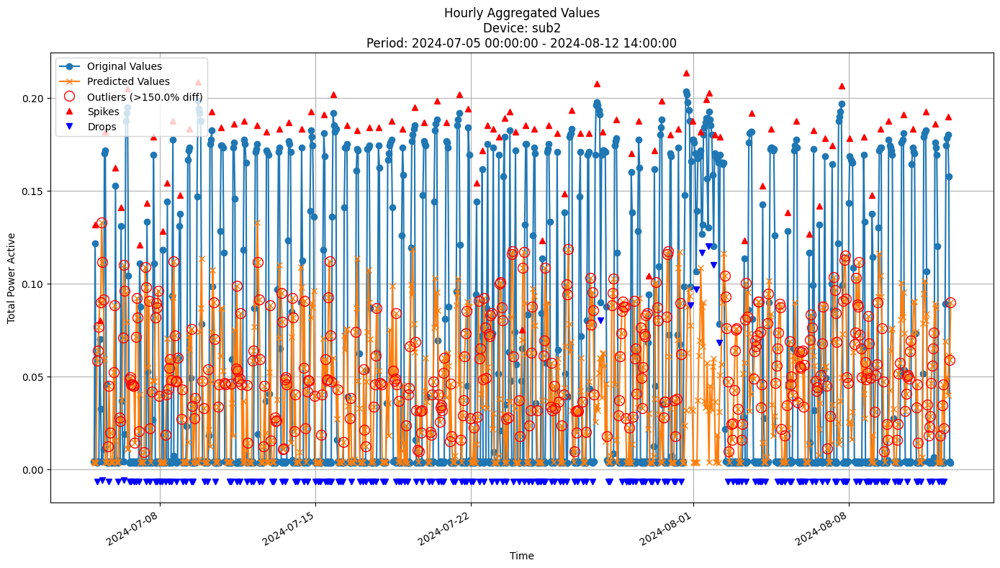


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0758
MAE: 0.0582
MAPE: 587.7952%

Directional Metrics:
Directional Accuracy: 49.3521%
First-Diff Correlation: 0.0125

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [11]:
join_periods = [-2, -1]
# Device iteration
for device_id in bl_mean_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, bl_mean_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, bl_mean_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### Baseline model (predict previous value)

In [12]:
update_freq = "1H"
bl_prev = PreviousValueRegressor
bl_prev_params = {}

In [13]:
bl_prev_train_period_predictions, bl_prev_valid_period_predictions,\
bl_prev_train_period_metrics, bl_prev_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=bl_prev,
    model_params=bl_prev_params,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    verbose=True
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-07-04 23:00:00+02:00
Model's memory usage: 0.000420 MB
Metrics for Device: sub3 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0131
	MAE: 0.0073
	MAPE: 1.7045%

Directional Metrics:
	Directional Accuracy: 51.1177%
	First-Diff Correlation: 0.1186

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 0.9583
		F1: 0.9787
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Daily

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-08-01 23:00:00+02:00
Model's memory usage: 0.000397 MB
Metrics for Device: sub3 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0118
	MAE: 0.0071
	MAPE: 1.5945%

Directional Metrics:
	Directional Accuracy: 50.7874%
	First-Diff Correlation: 0.3810

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Daily

#### Results

In [14]:
print("\n\nValid period metrics:")
bl_prev_all_time_valid_metrics = all_time_aggregation_metrics(bl_prev_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: sub3
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0125 ± 0.0006
	MAE: 0.0072 ± 0.0001
	MAPE: 1.6495% ± 0.0550%

	Directional Metrics:
		Directional Accuracy: 50.9526% ± 0.1652%
		First-Diff Correlation: 0.2498 ± 0.1312

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 1.0000 ± 0.0000
		Spike Recall: 0.9792 ± 0.0208
		Spike F1: 0.9894 ± 0.0106
		Drop Precision: 1.0000 ± 0.0000
		Drop Recall: 1.0000 ± 0.0000
		Drop F1: 1.0000 ± 0.0000
Daily Metrics:
	RMSE: 0.0167 ± 0.0076
	MAE: 0.0106 ± 0.0034
	MAPE: 0.1238% ± 0.0515%

	Directional Metrics:
		Directional Accuracy: 100.0000% ± 0.0000%
		First-Diff Correlation: 0.9996 ± 0.0003

	Immediate Detection (delta=0):
		Spike

#### Validation plots

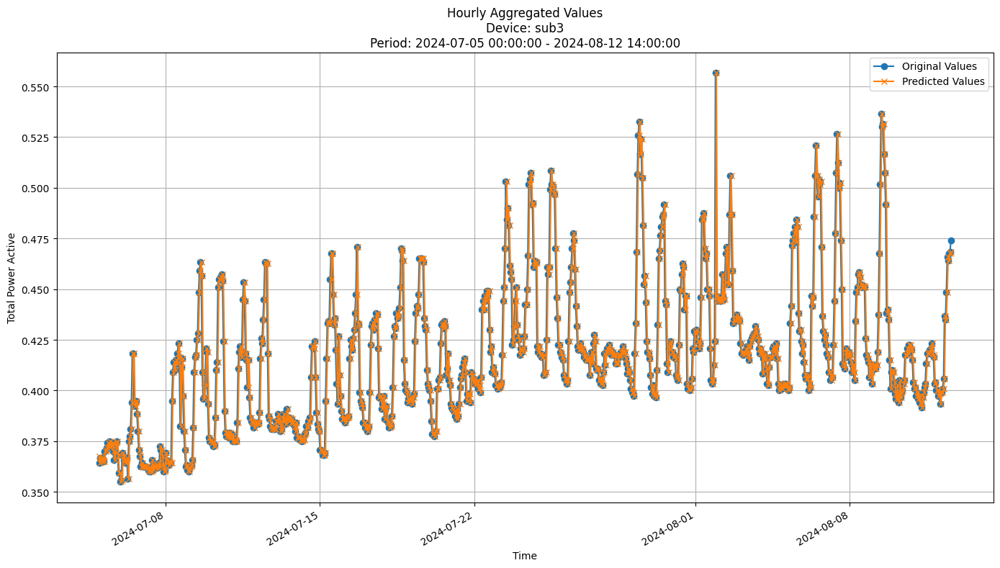


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0128
MAE: 0.0072
MAPE: 1.6742%

Directional Metrics:
Directional Accuracy: 51.0799%
First-Diff Correlation: 0.1775

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


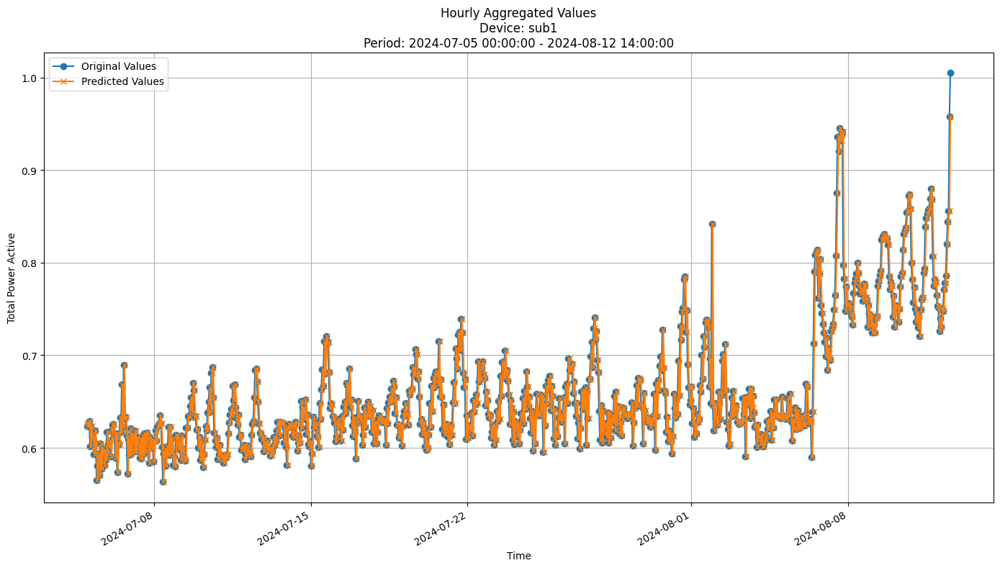


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0250
MAE: 0.0181
MAPE: 2.7465%

Directional Metrics:
Directional Accuracy: 37.0410%
First-Diff Correlation: -0.3698

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


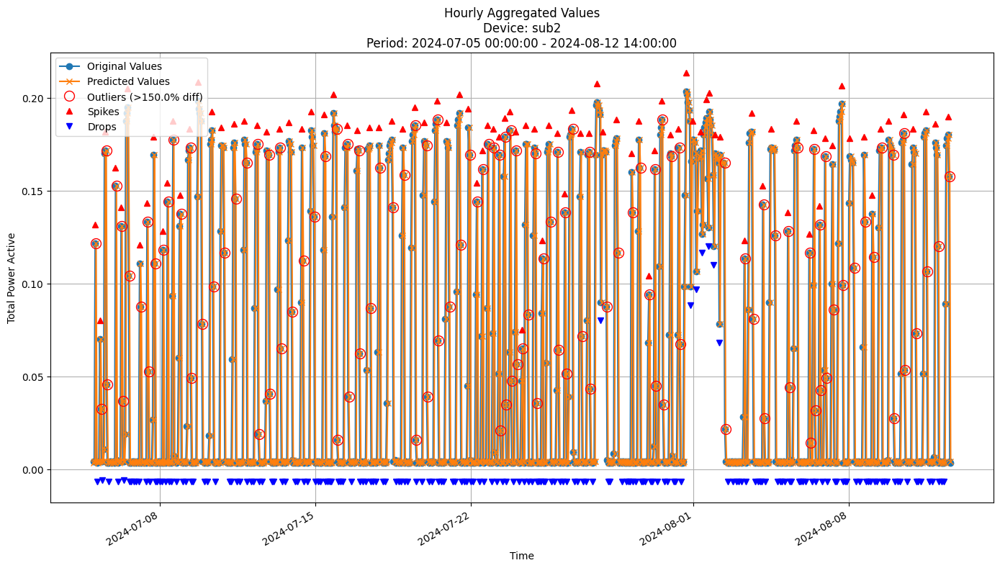


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0589
MAE: 0.0323
MAPE: 250.5989%

Directional Metrics:
Directional Accuracy: 41.5767%
First-Diff Correlation: 0.1032

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


In [15]:
join_periods = [-2, -1]
# Device iteration
for device_id in bl_prev_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, bl_prev_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, bl_prev_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### GBDT

In [16]:
update_freq = "14D"  # Update the model every 14 days
gbdt = GradientBoostingRegressor
# gbdt_params = {
#     'n_estimators': 100,
#     'learning_rate': 0.03,
#     'subsample': 0.8,
#     'max_depth': 10,
#     'random_state': 42
# }
gbdt_params = {'n_estimators': 100, 
 'learning_rate': 0.05, 
 'max_depth': 3, 
 'subsample': 0.6, 
 'random_state': 42}

In [17]:
gbdt_train_period_predictions, gbdt_valid_period_predictions, \
gbdt_train_period_metrics, gbdt_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=gbdt,
    model_params=gbdt_params,
    train=train, 
    valid=valid, 
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]


Retraining model on data from 2024-06-07 00:00:00+02:00 to 2024-07-04 23:00:00+02:00

Time: 0.09 seconds
Predicting for chunk from 2024-07-05 00:00:00+02:00 to 2024-07-19 00:00:00+02:00

-------------------------

Retraining model on data from 2024-06-07 00:00:00+02:00 to 2024-07-19 00:00:00+02:00

Time: 0.10 seconds
Predicting for chunk from 2024-07-19 01:00:00+02:00 to 2024-08-01 23:00:00+02:00

-------------------------
Model's memory usage: 0.010811 MB
Metrics for Device: sub3 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0206
	MAE: 0.0138
	MAPE: 3.1607%

Directional Metrics:
	Directional Accuracy: 55.5887%
	First-Diff Correlation: 0.2218

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1429
		Recall: 0.1250
		F1: 0.1333
	Drops:
		Precision: 0.1500
		Recall: 0.1200
		F1: 0.1333

Delayed Detection (delta=1 

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]


Retraining model on data from 2024-06-07 00:00:00+02:00 to 2024-08-01 23:00:00+02:00

Time: 0.11 seconds
Predicting for chunk from 2024-08-02 00:00:00+02:00 to 2024-08-12 14:00:00+02:00

-------------------------
Model's memory usage: 0.010620 MB
Metrics for Device: sub3 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0217
	MAE: 0.0184
	MAPE: 4.3223%

Directional Metrics:
	Directional Accuracy: 50.7874%
	First-Diff Correlation: 0.1754

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0769
		Recall: 0.1667
		F1: 0.1053
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.2308
		Recall: 0.5000
		F1: 0.3158
	Drops:
		Precision: 0.0714
		Recall: 0.1429
		F1: 0.0952
--------------------------------------------------

#### Results

In [18]:
print("\n\nTrain period metrics:")
gbdt_all_time_train_metrics = all_time_aggregation_metrics(gbdt_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
gbdt_all_time_valid_metrics = all_time_aggregation_metrics(gbdt_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub3
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0100 ± 0.0011
	MAE: 0.0072 ± 0.0007
	MAPE: 1.8463% ± 0.1347%

	Directional Metrics:
		Directional Accuracy: 58.1007% ± 0.3196%
		First-Diff Correlation: 0.4608 ± 0.0348

	Immediate Detection (delta=0):
		Spike Precision: 0.2454 ± 0.0403
		Spike Recall: 0.2316 ± 0.0411
		Spike F1: 0.2383 ± 0.0408
		Drop Precision: 0.2250 ± 0.0250
		Drop Recall: 0.1920 ± 0.0254
		Drop F1: 0.2072 ± 0.0254

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.6044 ± 0.0147
		Spike Recall: 0.5693 ± 0.0216
		Spike F1: 0.5863 ± 0.0184
		Drop Precision: 0.4250 ± 0.0750
		Drop Recall: 0.3632 ± 0.0716
		Drop F1: 0.3916 ± 0.0735
Daily Metrics:
	RMSE: 0.0642 ± 0.0066
	MAE: 0.0528 ± 0.0062
	MAPE: 0.5745% ± 0.0545%

	Directional Metrics:
		Directional Accuracy: 92.6936% ± 3.6027%
		First-Diff Correlation: 0.9827 ± 0.0024

	Immediate Detection (delta=0):
		Spike 

#### Training plots

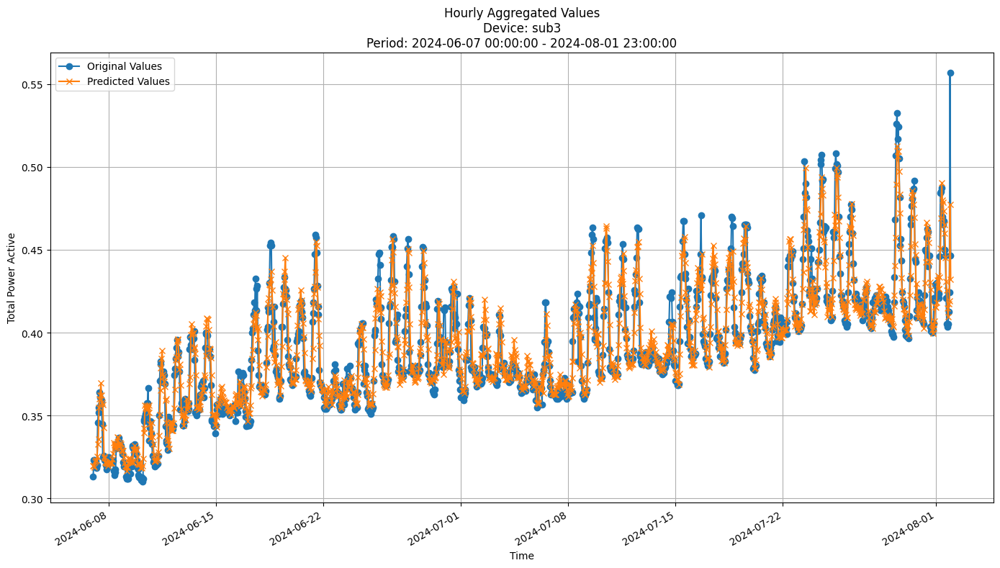


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0111
MAE: 0.0079
MAPE: 1.9810%

Directional Metrics:
Directional Accuracy: 57.7811%
First-Diff Correlation: 0.4259

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


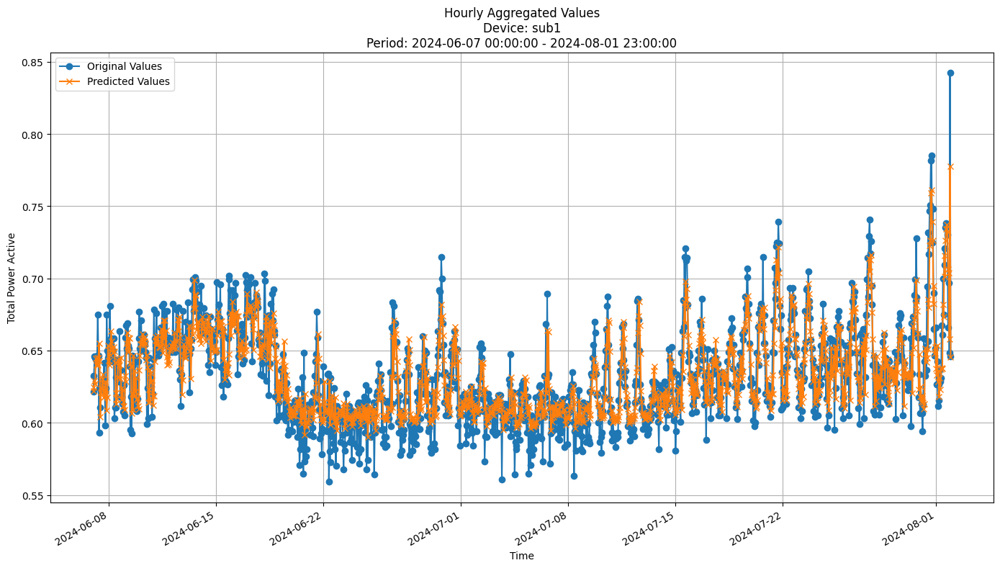


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0176
MAE: 0.0134
MAPE: 2.1227%

Directional Metrics:
Directional Accuracy: 59.0469%
First-Diff Correlation: 0.4560

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


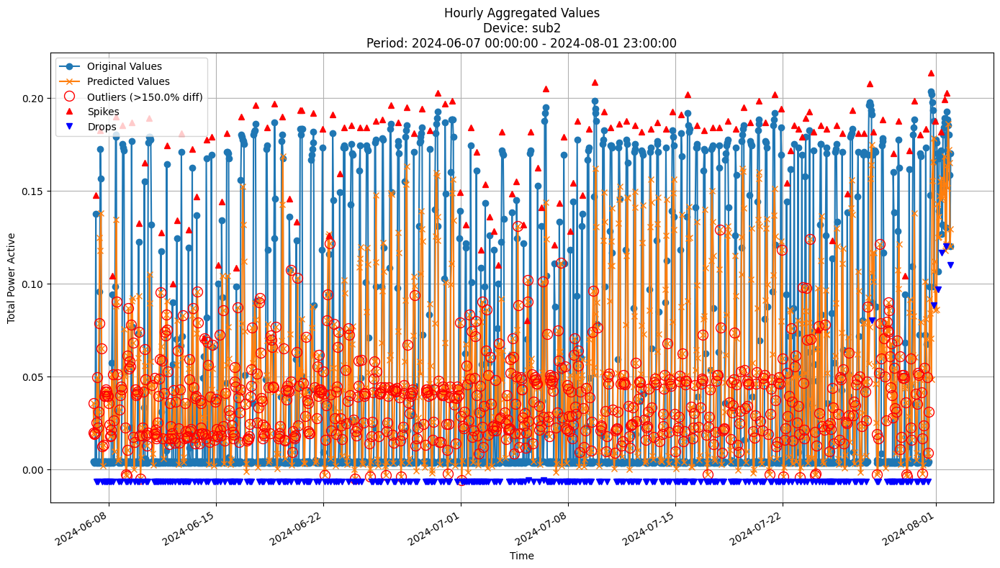


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0513
MAE: 0.0394
MAPE: 498.9588%

Directional Metrics:
Directional Accuracy: 54.1325%
First-Diff Correlation: 0.3654

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [19]:
for device_id in gbdt_train_period_predictions.keys():
    y_train = gbdt_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = gbdt_train_period_predictions[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last few periods of predictions

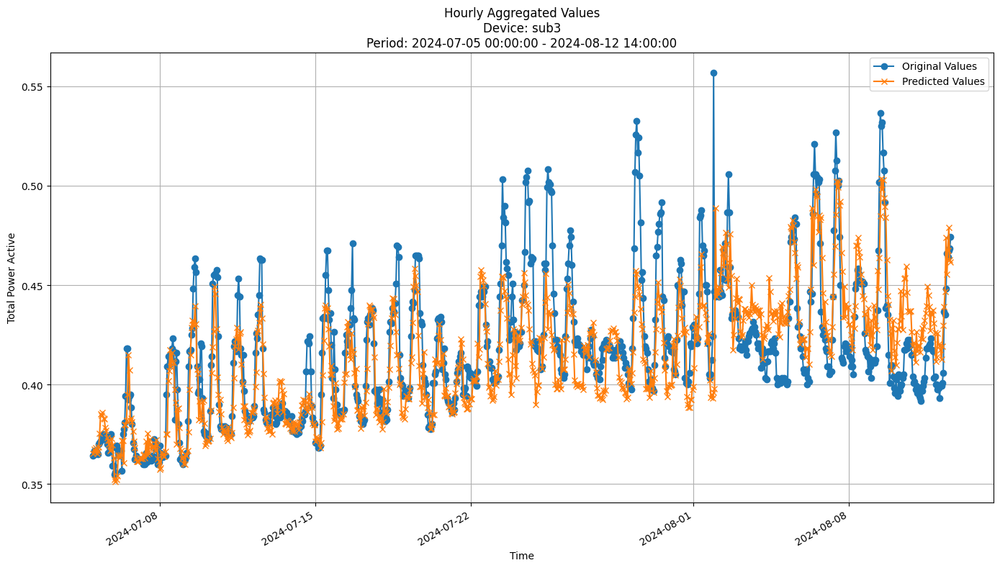


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0209
MAE: 0.0151
MAPE: 3.4802%

Directional Metrics:
Directional Accuracy: 54.2117%
First-Diff Correlation: 0.1935

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


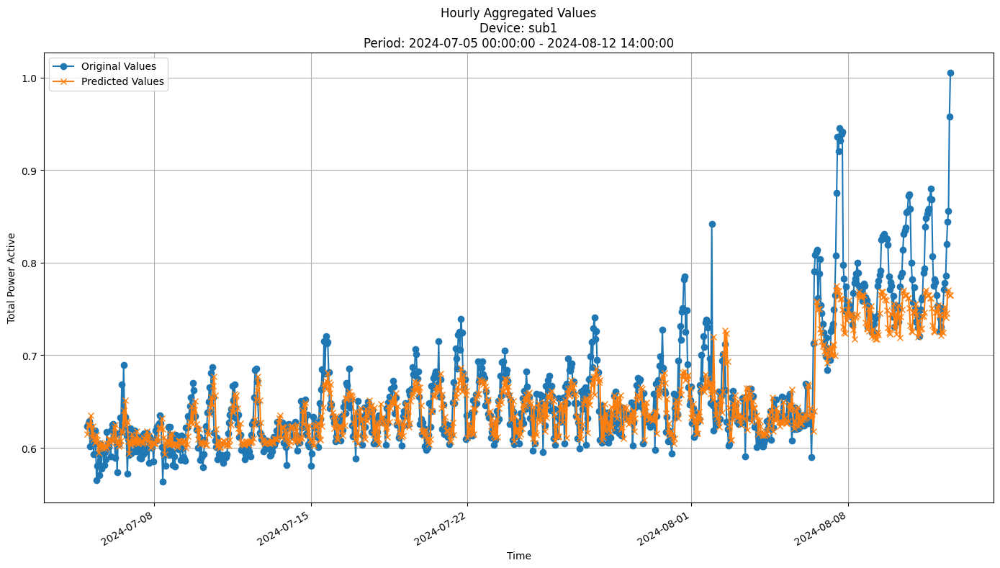


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0343
MAE: 0.0218
MAPE: 3.1087%

Directional Metrics:
Directional Accuracy: 57.5594%
First-Diff Correlation: 0.2175

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


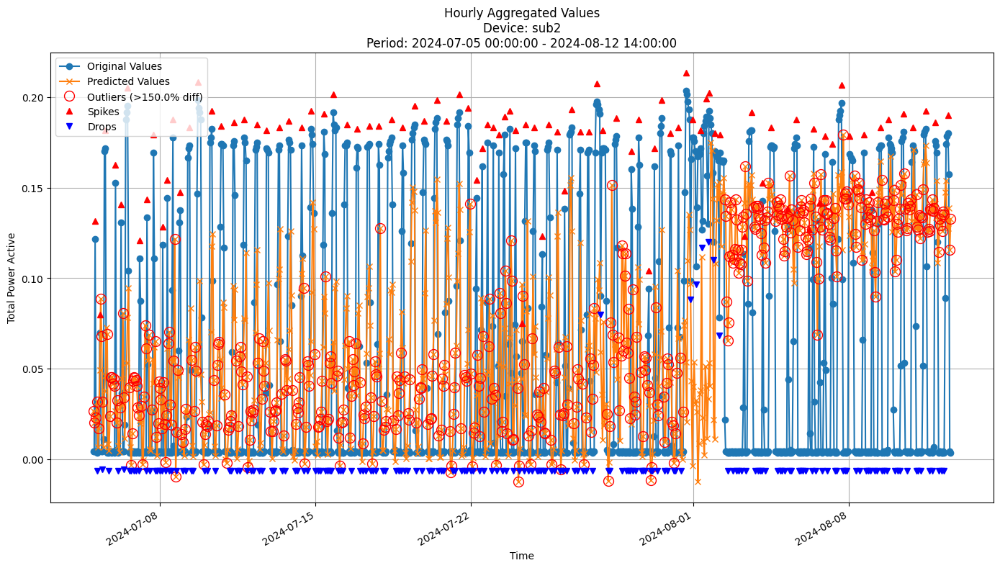


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0773
MAE: 0.0603
MAPE: 895.2925%

Directional Metrics:
Directional Accuracy: 51.2959%
First-Diff Correlation: 0.2109

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [20]:
join_periods = [-2, -1]
# Device iteration
for device_id in gbdt_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, gbdt_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, gbdt_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Random Forest model

In [21]:
update_freq = "14D"  # Update the model every 14 days
rf = RandomForestRegressor
rf_params = {'n_estimators': 300, 
 'max_depth': 7, 
 'max_features': 1.0, 
 'random_state': 42, 
 'n_jobs': -1}

In [22]:
rf_train_period_predictions, rf_valid_period_predictions, \
rf_train_period_metrics, rf_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=rf, 
    model_params=rf_params,
    train=train, 
    valid=valid, 
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]


Retraining model on data from 2024-06-07 00:00:00+02:00 to 2024-07-04 23:00:00+02:00

Time: 0.35 seconds
Predicting for chunk from 2024-07-05 00:00:00+02:00 to 2024-07-19 00:00:00+02:00

-------------------------

Retraining model on data from 2024-06-07 00:00:00+02:00 to 2024-07-19 00:00:00+02:00

Time: 0.31 seconds
Predicting for chunk from 2024-07-19 01:00:00+02:00 to 2024-08-01 23:00:00+02:00

-------------------------
Model's memory usage: 0.119888 MB
Metrics for Device: sub3 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0224
	MAE: 0.0154
	MAPE: 3.5556%

Directional Metrics:
	Directional Accuracy: 57.9732%
	First-Diff Correlation: 0.1709

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1538
		Recall: 0.1667
		F1: 0.1600
	Drops:
		Precision: 0.0769
		Recall: 0.0800
		F1: 0.0784

Delayed Detection (delta=1 

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]


Retraining model on data from 2024-06-07 00:00:00+02:00 to 2024-08-01 23:00:00+02:00

Time: 0.31 seconds
Predicting for chunk from 2024-08-02 00:00:00+02:00 to 2024-08-12 14:00:00+02:00

-------------------------
Model's memory usage: 0.119881 MB
Metrics for Device: sub3 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0222
	MAE: 0.0183
	MAPE: 4.2666%

Directional Metrics:
	Directional Accuracy: 47.2441%
	First-Diff Correlation: 0.2067

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0909
		Recall: 0.1667
		F1: 0.1176
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.2727
		Recall: 0.5000
		F1: 0.3529
	Drops:
		Precision: 0.2727
		Recall: 0.4286
		F1: 0.3333
--------------------------------------------------

#### Results

In [23]:
print("\n\nTrain period metrics:")
rf_all_time_train_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
rf_all_time_valid_metrics = all_time_aggregation_metrics(rf_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub3
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0078 ± 0.0012
	MAE: 0.0055 ± 0.0008
	MAPE: 1.4008% ± 0.1692%

	Directional Metrics:
		Directional Accuracy: 65.5871% ± 1.4769%
		First-Diff Correlation: 0.6550 ± 0.0502

	Immediate Detection (delta=0):
		Spike Precision: 0.4131 ± 0.0631
		Spike Recall: 0.3939 ± 0.0606
		Spike F1: 0.4033 ± 0.0618
		Drop Precision: 0.3167 ± 0.0167
		Drop Recall: 0.2663 ± 0.0163
		Drop F1: 0.2893 ± 0.0166

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.7298 ± 0.0798
		Spike Recall: 0.6959 ± 0.0768
		Spike F1: 0.7124 ± 0.0783
		Drop Precision: 0.5564 ± 0.0436
		Drop Recall: 0.4674 ± 0.0326
		Drop F1: 0.5080 ± 0.0374
Daily Metrics:
	RMSE: 0.0505 ± 0.0071
	MAE: 0.0403 ± 0.0073
	MAPE: 0.4320% ± 0.0668%

	Directional Metrics:
		Directional Accuracy: 94.5118% ± 1.7845%
		First-Diff Correlation: 0.9850 ± 0.0005

	Immediate Detection (delta=0):
		Spike 

#### Training plots
Plot only the last period of predictions

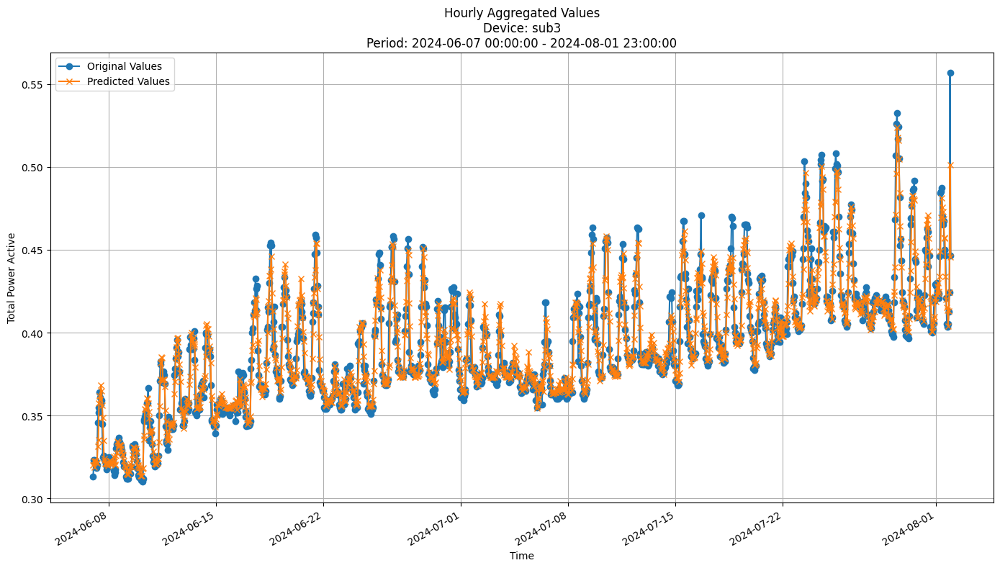


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0090
MAE: 0.0063
MAPE: 1.5700%

Directional Metrics:
Directional Accuracy: 64.1102%
First-Diff Correlation: 0.6048

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


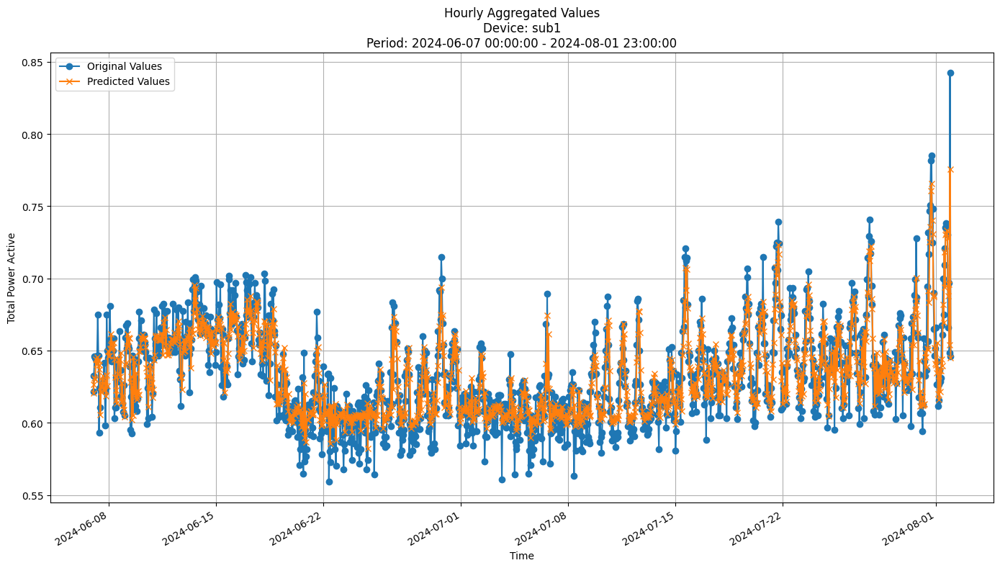


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0147
MAE: 0.0115
MAPE: 1.8142%

Directional Metrics:
Directional Accuracy: 70.2159%
First-Diff Correlation: 0.6533

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


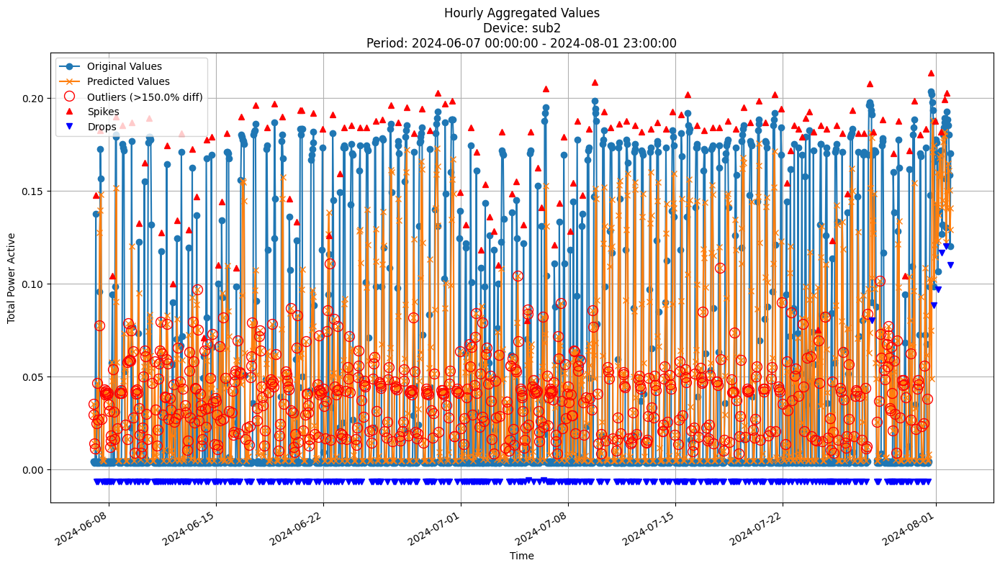


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0475
MAE: 0.0347
MAPE: 431.6961%

Directional Metrics:
Directional Accuracy: 57.0365%
First-Diff Correlation: 0.4984

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [24]:
for device_id in rf_train_period_predictions.keys():
    y_train = rf_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = rf_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last periods of predictions

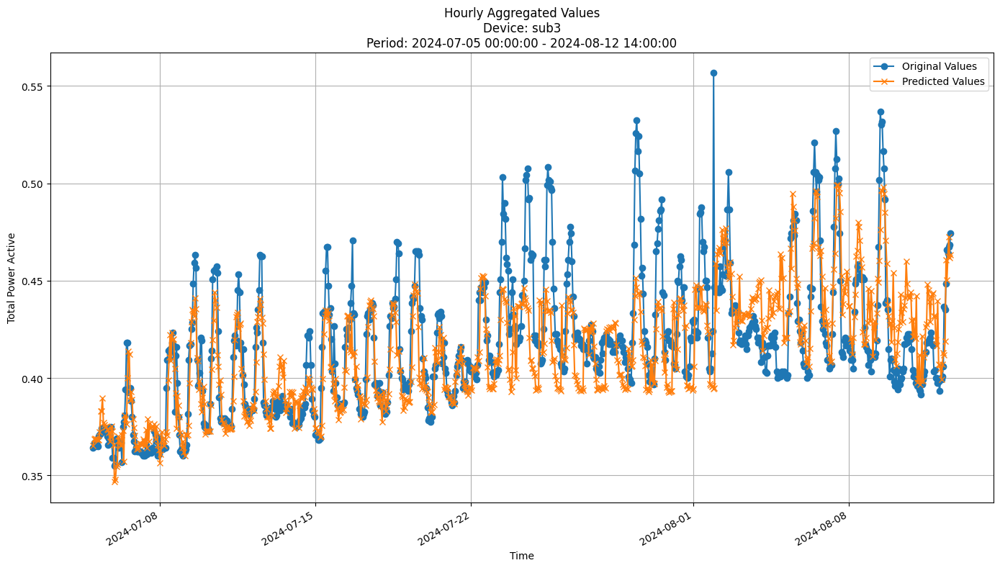


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0223
MAE: 0.0162
MAPE: 3.7512%

Directional Metrics:
Directional Accuracy: 54.9676%
First-Diff Correlation: 0.1742

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


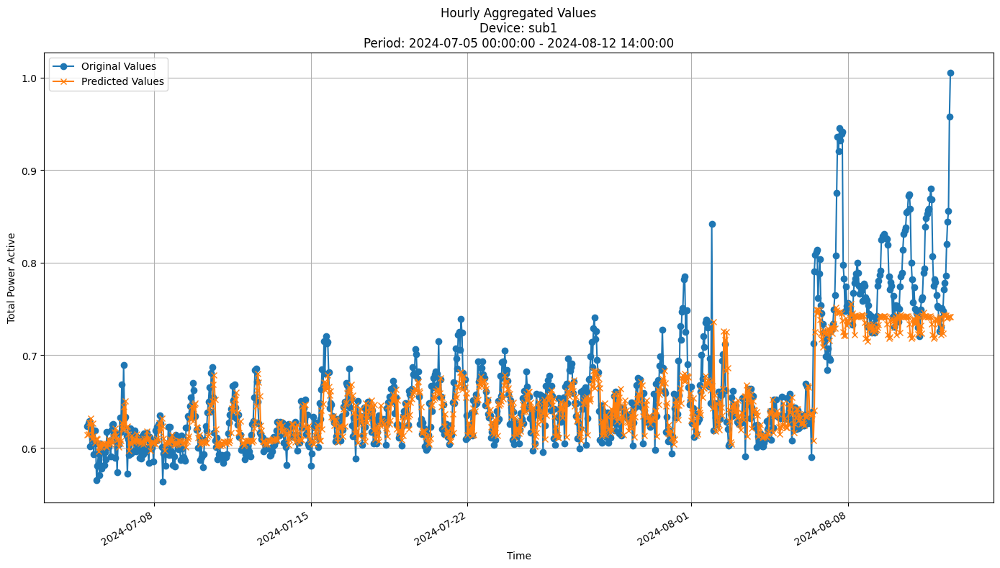


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0375
MAE: 0.0233
MAPE: 3.3054%

Directional Metrics:
Directional Accuracy: 55.8315%
First-Diff Correlation: 0.1771

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


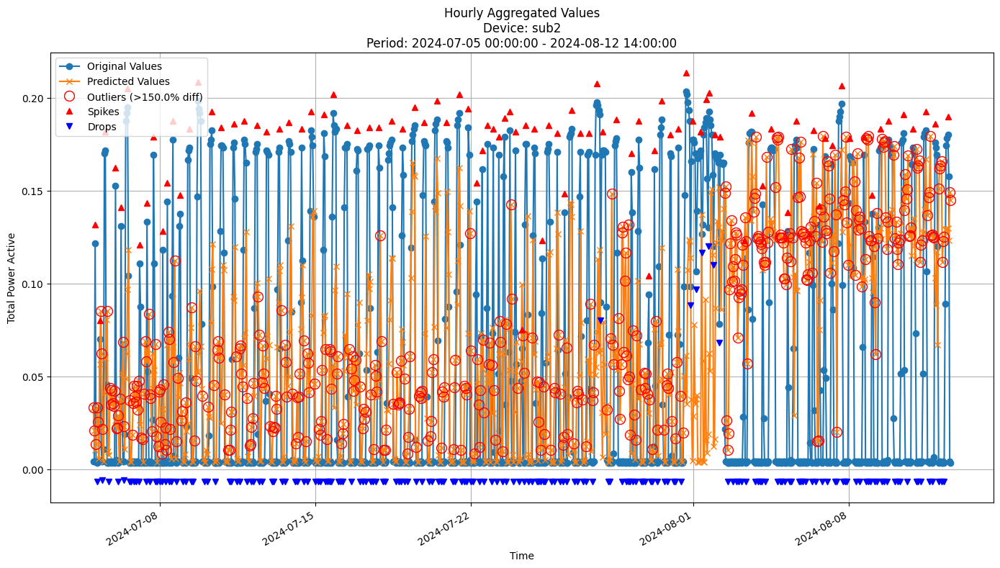


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0785
MAE: 0.0606
MAPE: 884.1022%

Directional Metrics:
Directional Accuracy: 50.5400%
First-Diff Correlation: 0.1871

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [25]:
join_periods = [-2, -1]
# Device iteration
for device_id in rf_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, rf_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, rf_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Hoeffding Tree

In [26]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

hoef = HoeffdingTreeRegressor
# hoef_params = {
#     'grace_period': 10,
#     'delta': 0.5,
#     'max_depth': 10,
#     'tau': 0.05,
#     'leaf_prediction': 'mean'
# }
hoef_params = {'max_depth': 10,
'grace_period': 96,
'tau': 0.001,
'delta': 0.005}

In [27]:
hoef_all_train_preds, hoef_all_valid_preds, \
hoef_all_train_metrics, hoef_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=hoef, 
    model_params=hoef_params,
    train=train, 
    valid=valid, 
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-07-04 23:00:00+02:00
Model's memory usage: 0.123154 MB
Metrics for Device: sub3 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0333
	MAE: 0.0264
	MAPE: 6.1531%

Directional Metrics:
	Directional Accuracy: 47.8390%
	First-Diff Correlation: 0.1379

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.2353
		Recall: 0.1667
		F1: 0.1951
	Drops:
		Precision: 0.3529
		Recall: 0.2400
		F1: 0.2857
--------------------------------------------------
Daily

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-08-01 23:00:00+02:00
Model's memory usage: 0.125198 MB
Metrics for Device: sub3 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0337
	MAE: 0.0286
	MAPE: 6.4889%

Directional Metrics:
	Directional Accuracy: 48.0315%
	First-Diff Correlation: 0.2116

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1667
		Recall: 0.1667
		F1: 0.1667
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.1667
		Recall: 0.1667
		F1: 0.1667
	Drops:
		Precision: 0.1667
		Recall: 0.1429
		F1: 0.1538
--------------------------------------------------
Daily

#### Results

In [28]:
print("\n\nTrain period metrics:")
hoef_all_time_train_metrics = all_time_aggregation_metrics(hoef_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
hoef_all_time_valid_metrics = all_time_aggregation_metrics(hoef_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub3
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0324 ± 0.0030
	MAE: 0.0258 ± 0.0027
	MAPE: 6.9064% ± 0.5503%

	Directional Metrics:
		Directional Accuracy: 10.4654% ± 0.4803%
		First-Diff Correlation: 0.1440 ± 0.0641

	Immediate Detection (delta=0):
		Spike Precision: 0.0875 ± 0.0875
		Spike Recall: 0.0833 ± 0.0833
		Spike F1: 0.0854 ± 0.0854
		Drop Precision: 0.1474 ± 0.0192
		Drop Recall: 0.1377 ± 0.0290
		Drop F1: 0.1422 ± 0.0245

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2375 ± 0.2375
		Spike Recall: 0.2262 ± 0.2262
		Spike F1: 0.2317 ± 0.2317
		Drop Precision: 0.3205 ± 0.0128
		Drop Recall: 0.2971 ± 0.0362
		Drop F1: 0.3078 ± 0.0255
Daily Metrics:
	RMSE: 0.6502 ± 0.1012
	MAE: 0.5072 ± 0.1076
	MAPE: 5.7365% ± 1.0414%

	Directional Metrics:
		Directional Accuracy: 33.9394% ± 0.6061%
		First-Diff Correlation: 0.6079 ± 0.0133

	Immediate Detection (delta=0):
		Spike 

#### Training plots
Plot only the last period of predictions

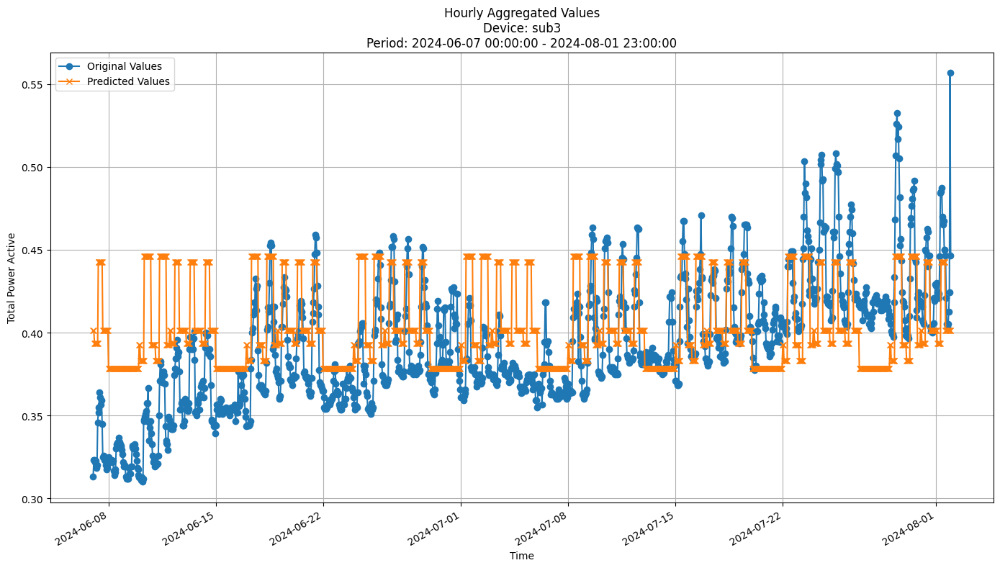


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0354
MAE: 0.0284
MAPE: 7.4567%

Directional Metrics:
Directional Accuracy: 10.9456%
First-Diff Correlation: 0.2081

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


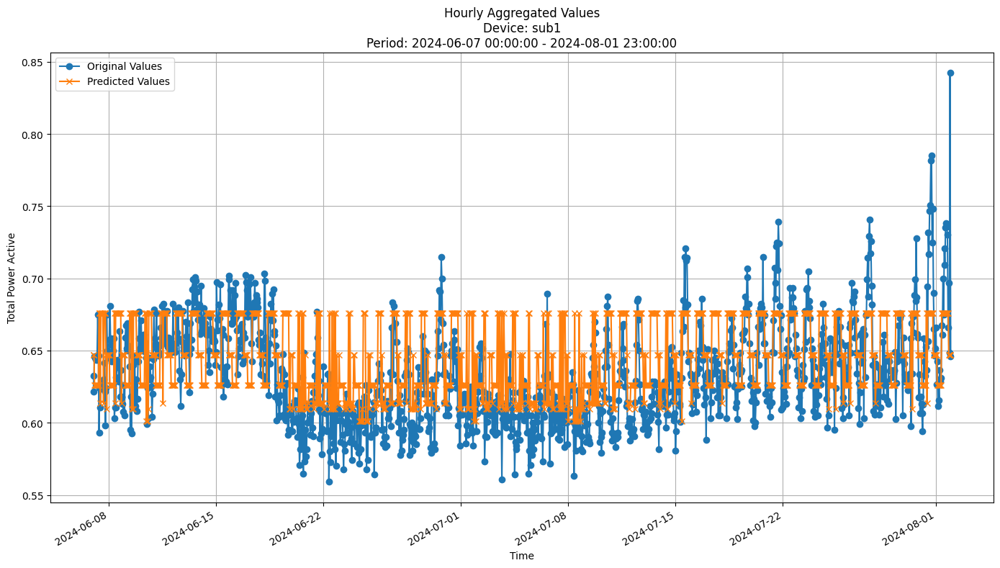


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0339
MAE: 0.0265
MAPE: 4.2211%

Directional Metrics:
Directional Accuracy: 15.4877%
First-Diff Correlation: 0.0555

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


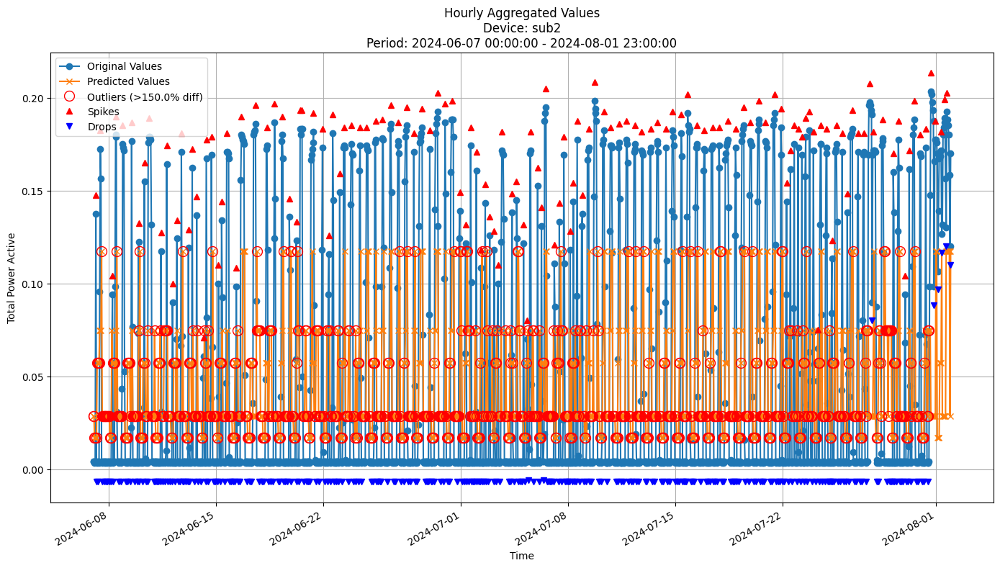


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0649
MAE: 0.0505
MAPE: 590.1064%

Directional Metrics:
Directional Accuracy: 18.9873%
First-Diff Correlation: 0.0932

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [29]:
for device_id in hoef_all_train_preds.keys():
    y_train = hoef_all_train_preds[device_id][-1]['y_true']
    y_pred_train = hoef_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

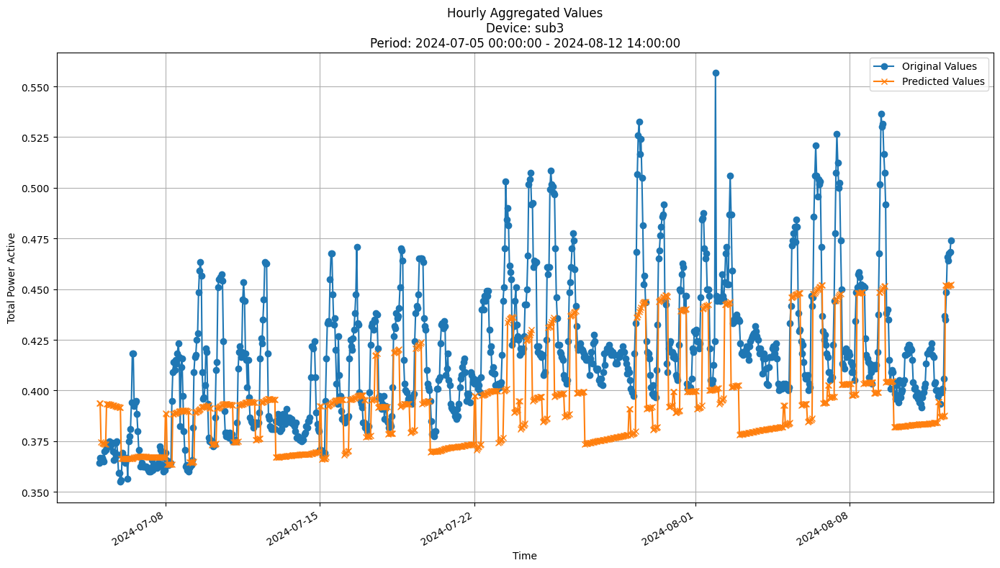


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0334
MAE: 0.0270
MAPE: 6.2454%

Directional Metrics:
Directional Accuracy: 47.8402%
First-Diff Correlation: 0.1583

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


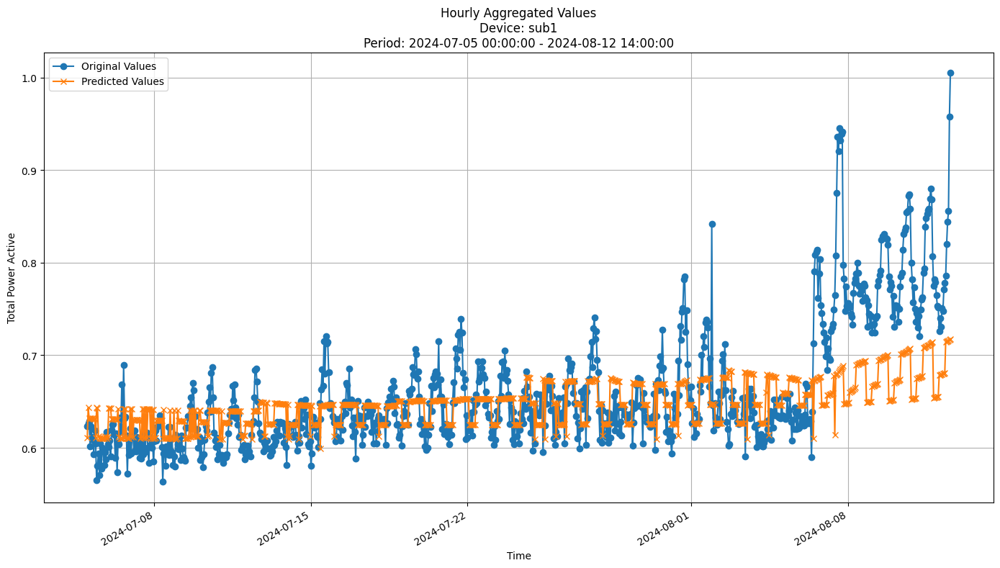


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0550
MAE: 0.0373
MAPE: 5.2794%

Directional Metrics:
Directional Accuracy: 45.4644%
First-Diff Correlation: 0.0801

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


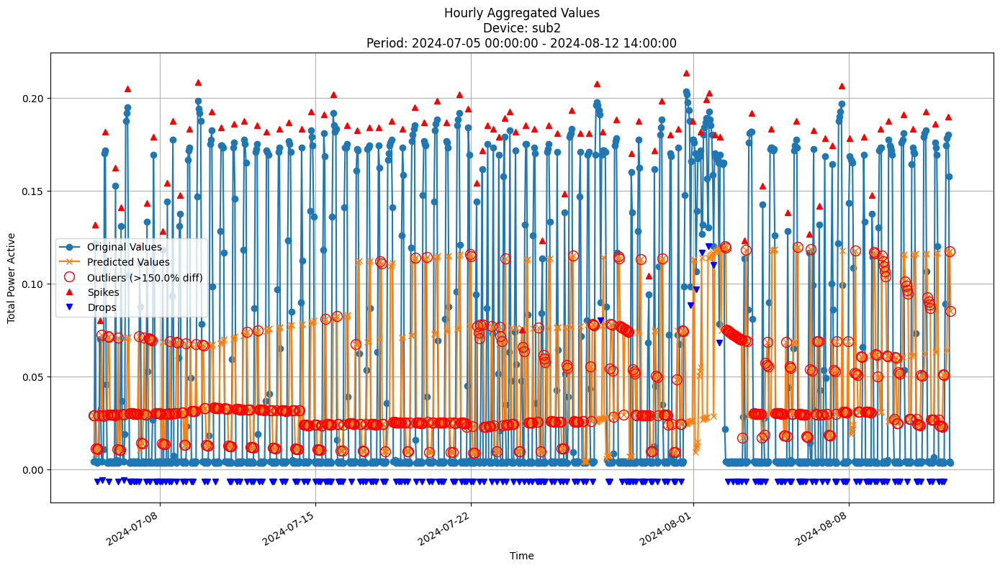


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0706
MAE: 0.0547
MAPE: 546.3045%

Directional Metrics:
Directional Accuracy: 43.6285%
First-Diff Correlation: 0.1126

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [30]:
join_periods = [-2, -1]
# Device iteration
for device_id in hoef_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, hoef_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, hoef_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (Hoeffding Tree)

In [31]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

arf_hf = ARFRegressor
arf_hf_params = {
    'n_models': 10,
    'max_features': 0.8,
    'aggregation_method': 'median',
    'grace_period': 10,
    'max_depth': 10,
    'delta': 0.5,  # split confidence
    'tau': 0.01,  # break ties
    'seed': 42
}

In [32]:
arf_hf_all_train_preds, arf_hf_all_valid_preds, \
arf_hf_all_train_metrics, arf_hf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf_hf,
    model_params=arf_hf_params,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-07-04 23:00:00+02:00
Model's memory usage: 2.530678 MB
Metrics for Device: sub3 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0329
	MAE: 0.0269
	MAPE: 6.2895%

Directional Metrics:
	Directional Accuracy: 59.4635%
	First-Diff Correlation: 0.3498

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0952
		Recall: 0.0833
		F1: 0.0889
	Drops:
		Precision: 0.3000
		Recall: 0.2400
		F1: 0.2667

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.4286
		Recall: 0.3750
		F1: 0.4000
	Drops:
		Precision: 0.4000
		Recall: 0.3200
		F1: 0.3556
--------------------------------------------------
Daily

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-08-01 23:00:00+02:00
Model's memory usage: 2.739632 MB
Metrics for Device: sub3 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0343
	MAE: 0.0289
	MAPE: 6.5325%

Directional Metrics:
	Directional Accuracy: 57.0866%
	First-Diff Correlation: 0.4786

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1000
		Recall: 0.1667
		F1: 0.1250
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.1000
		Recall: 0.1667
		F1: 0.1250
	Drops:
		Precision: 0.1000
		Recall: 0.1429
		F1: 0.1176
--------------------------------------------------
Daily

#### Results

In [33]:
print("\n\nTrain period metrics:")
arf_hf_all_time_train_metrics = all_time_aggregation_metrics(arf_hf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_hf_all_time_valid_metrics = all_time_aggregation_metrics(arf_hf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub3
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0273 ± 0.0028
	MAE: 0.0211 ± 0.0026
	MAPE: 5.6606% ± 0.5270%

	Directional Metrics:
		Directional Accuracy: 50.1673% ± 0.8379%
		First-Diff Correlation: 0.4478 ± 0.0547

	Immediate Detection (delta=0):
		Spike Precision: 0.2306 ± 0.0737
		Spike Recall: 0.2543 ± 0.0639
		Spike F1: 0.2416 ± 0.0695
		Drop Precision: 0.1900 ± 0.0100
		Drop Recall: 0.1812 ± 0.0145
		Drop F1: 0.1847 ± 0.0028

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4851 ± 0.2106
		Spike Recall: 0.5303 ± 0.1970
		Spike F1: 0.5061 ± 0.2050
		Drop Precision: 0.3200 ± 0.0200
		Drop Recall: 0.3098 ± 0.0598
		Drop F1: 0.3134 ± 0.0407
Daily Metrics:
	RMSE: 0.5827 ± 0.0605
	MAE: 0.4492 ± 0.0577
	MAPE: 5.0720% ± 0.4967%

	Directional Metrics:
		Directional Accuracy: 63.2997% ± 0.3367%
		First-Diff Correlation: 0.6343 ± 0.0021

	Immediate Detection (delta=0):
		Spike 

#### Training plots

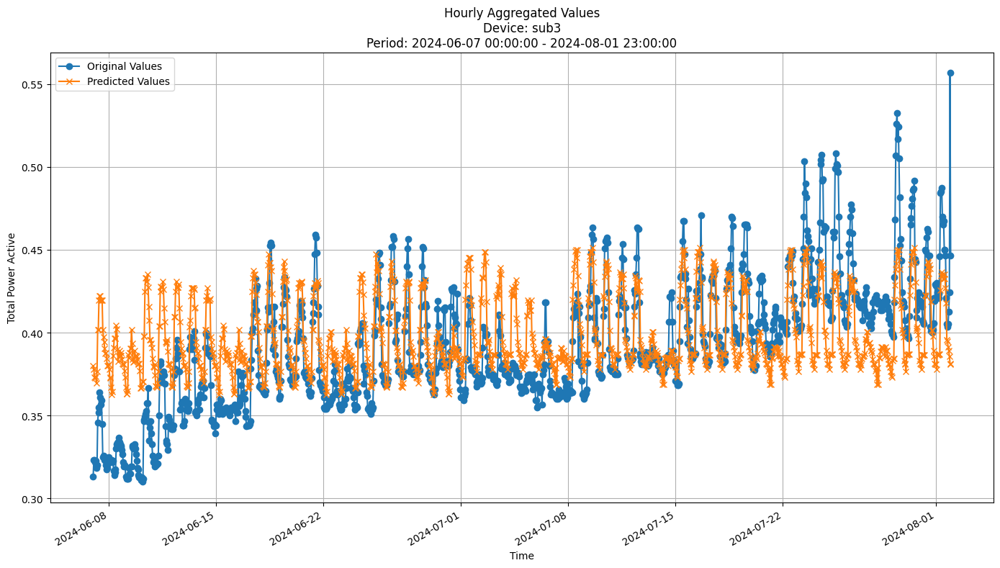


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0301
MAE: 0.0237
MAPE: 6.1876%

Directional Metrics:
Directional Accuracy: 51.0052%
First-Diff Correlation: 0.3931

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


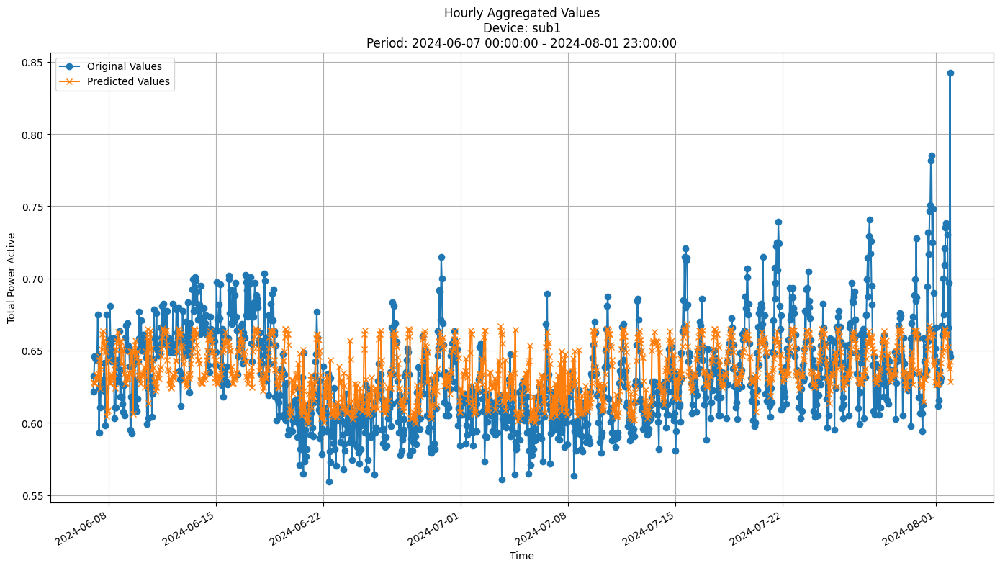


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0280
MAE: 0.0214
MAPE: 3.3663%

Directional Metrics:
Directional Accuracy: 52.1966%
First-Diff Correlation: 0.1467

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


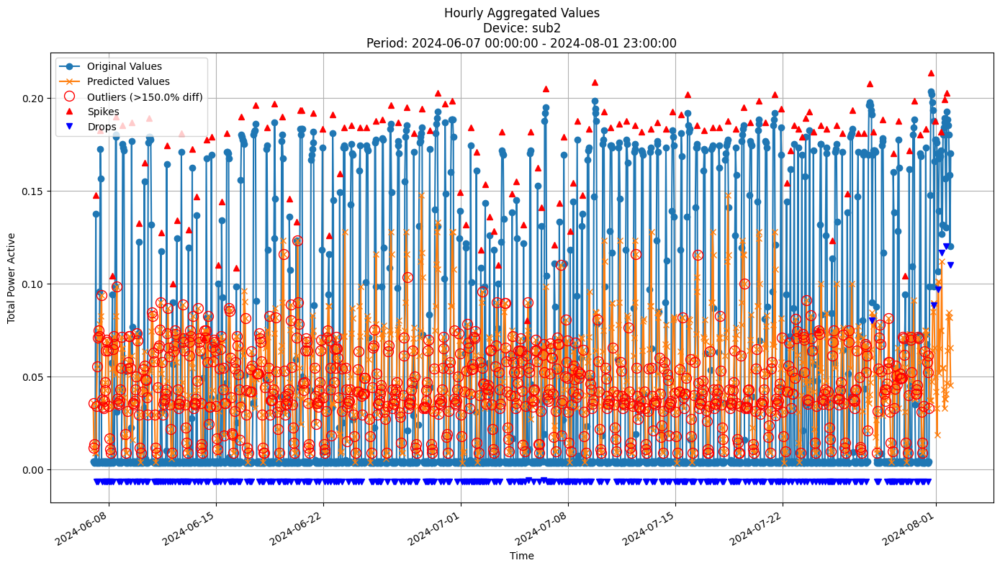


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0624
MAE: 0.0508
MAPE: 644.9240%

Directional Metrics:
Directional Accuracy: 49.2926%
First-Diff Correlation: 0.2057

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [34]:
for device_id in arf_hf_all_train_preds.keys():
    y_train = arf_hf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_hf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

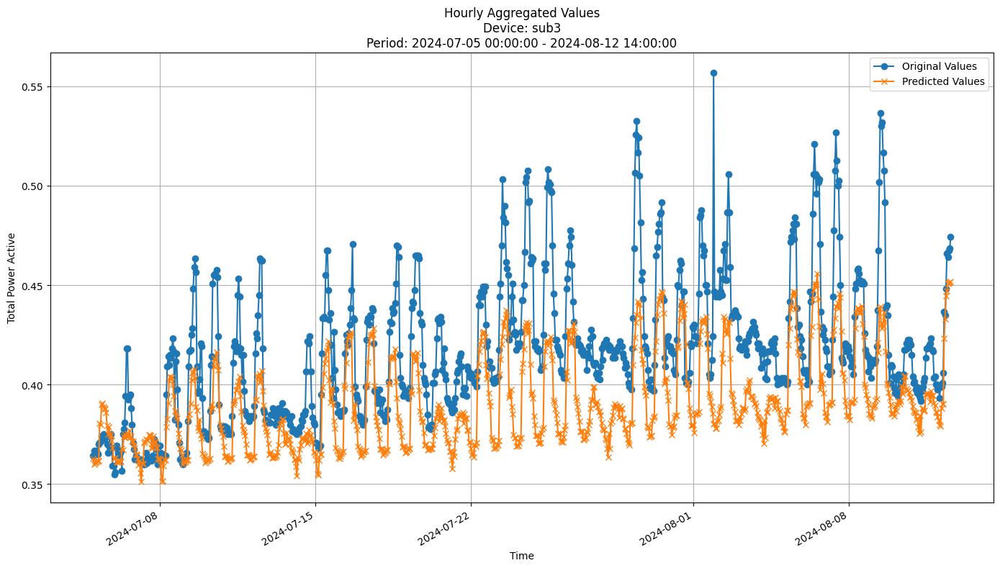


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0333
MAE: 0.0275
MAPE: 6.3563%

Directional Metrics:
Directional Accuracy: 58.8553%
First-Diff Correlation: 0.3830

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


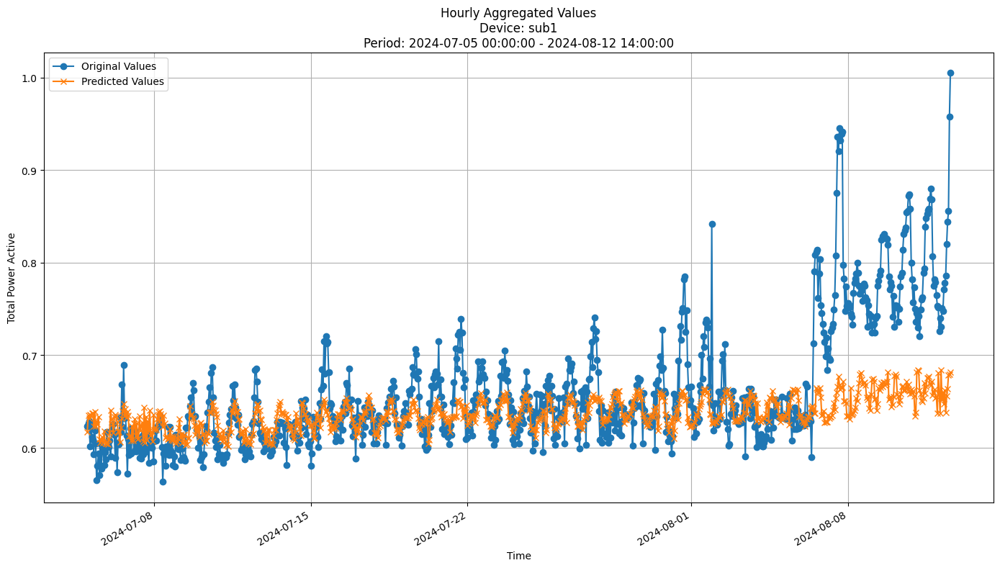


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0610
MAE: 0.0378
MAPE: 5.2232%

Directional Metrics:
Directional Accuracy: 52.6998%
First-Diff Correlation: 0.0692

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


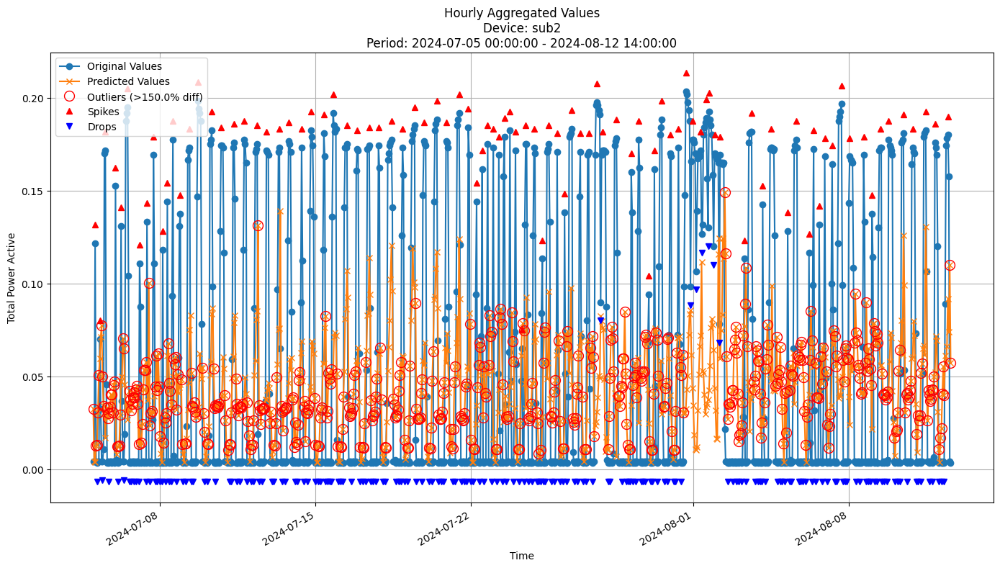


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0699
MAE: 0.0555
MAPE: 559.3082%

Directional Metrics:
Directional Accuracy: 48.5961%
First-Diff Correlation: 0.1069

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [35]:
join_periods = [-2, -1]
# Device iteration
for device_id in arf_hf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_hf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_hf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### FastODT

In [36]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

fodt = fastodt.FastODT
fodt_params = {'depth': 30, 
               'grace_period': 96, 
               'grace_period_depth': 0, 
               'split_confidence': 0.1, 
               'max_feature': 0.7, 
               'tie_threshold': 0.05, 
               'bin_type': 'adaptive', 
               'max_bins': 16, 
               'split_criterion': 'vr_rel'}

In [37]:
fodt_all_train_preds, fodt_all_valid_preds, \
fodt_all_train_metrics, fodt_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=fodt,
    model_params=fodt_params,
    train=train, 
    valid=valid, 
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-07-04 23:00:00+02:00
Model's memory usage: 3.968231 MB
Metrics for Device: sub3 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0219
	MAE: 0.0146
	MAPE: 3.4207%

Directional Metrics:
	Directional Accuracy: 45.7526%
	First-Diff Correlation: 0.1463

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2286
		Recall: 0.3333
		F1: 0.2712
	Drops:
		Precision: 0.1081
		Recall: 0.1600
		F1: 0.1290

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.3714
		Recall: 0.5417
		F1: 0.4407
	Drops:
		Precision: 0.2432
		Recall: 0.3600
		F1: 0.2903
--------------------------------------------------
Daily

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-08-01 23:00:00+02:00
Model's memory usage: 3.088860 MB
Metrics for Device: sub3 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0323
	MAE: 0.0243
	MAPE: 5.4291%

Directional Metrics:
	Directional Accuracy: 38.1890%
	First-Diff Correlation: 0.0114

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily

#### Results

In [38]:
print("\n\nTrain period metrics:")
fodt_all_time_train_metrics = all_time_aggregation_metrics(fodt_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
fodt_all_time_valid_metrics = all_time_aggregation_metrics(fodt_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub3
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0234 ± 0.0023
	MAE: 0.0155 ± 0.0015
	MAPE: 4.0728% ± 0.1670%

	Directional Metrics:
		Directional Accuracy: 38.9935% ± 2.4808%
		First-Diff Correlation: 0.0819 ± 0.0213

	Immediate Detection (delta=0):
		Spike Precision: 0.0670 ± 0.0045
		Spike Recall: 0.1039 ± 0.0325
		Spike F1: 0.0802 ± 0.0135
		Drop Precision: 0.1141 ± 0.0459
		Drop Recall: 0.1495 ± 0.0245
		Drop F1: 0.1275 ± 0.0392

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2277 ± 0.0818
		Spike Recall: 0.3788 ± 0.2121
		Spike F1: 0.2809 ± 0.1253
		Drop Precision: 0.2850 ± 0.0350
		Drop Recall: 0.4031 ± 0.0553
		Drop F1: 0.3284 ± 0.0049
Daily Metrics:
	RMSE: 0.3130 ± 0.0404
	MAE: 0.2258 ± 0.0042
	MAPE: 2.5549% ± 0.1052%

	Directional Metrics:
		Directional Accuracy: 78.9899% ± 9.8990%
		First-Diff Correlation: 0.7919 ± 0.0518

	Immediate Detection (delta=0):
		Spike 

#### Training plots

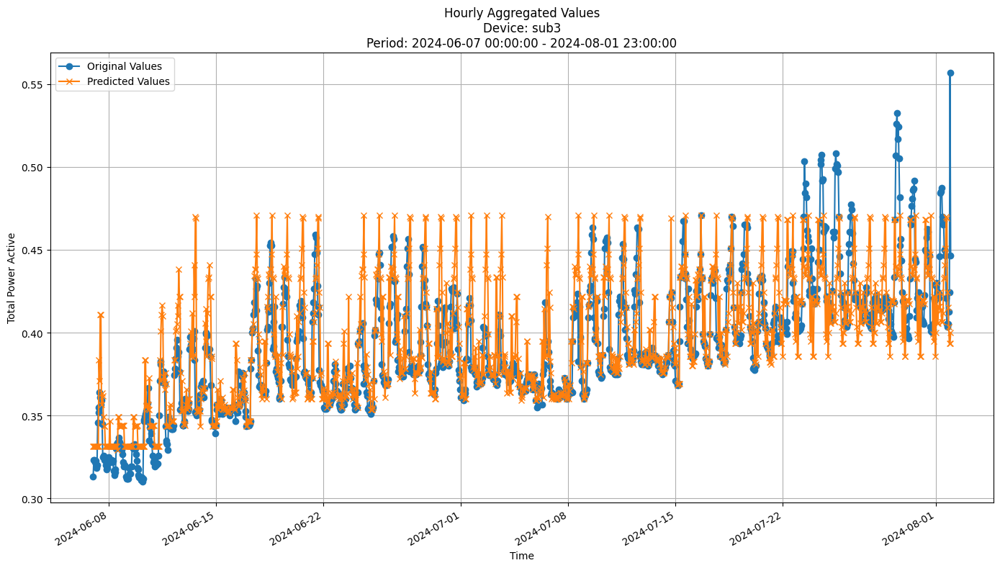


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0257
MAE: 0.0170
MAPE: 4.2398%

Directional Metrics:
Directional Accuracy: 41.4743%
First-Diff Correlation: 0.0607

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


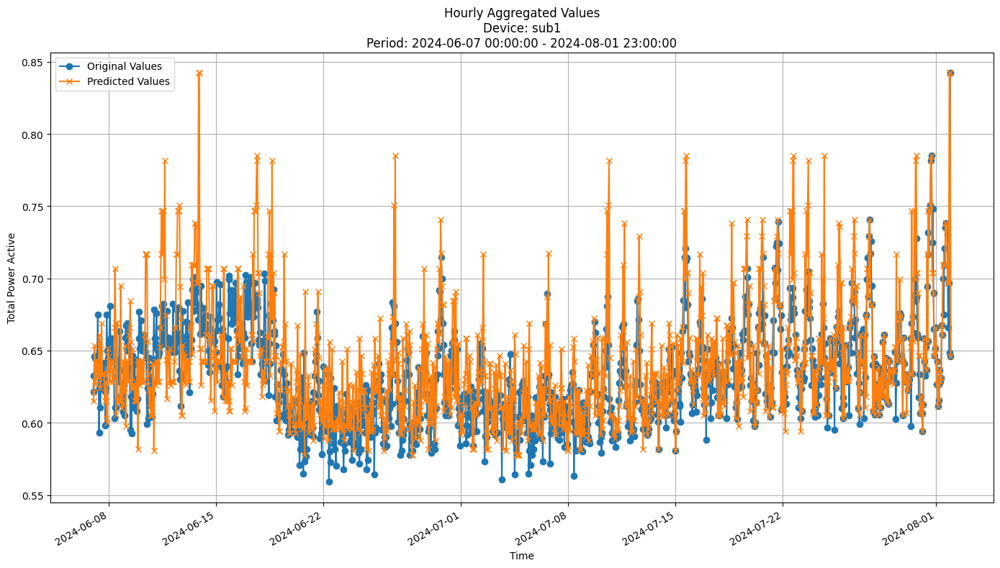


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0325
MAE: 0.0220
MAPE: 3.4691%

Directional Metrics:
Directional Accuracy: 50.9308%
First-Diff Correlation: 0.2343

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


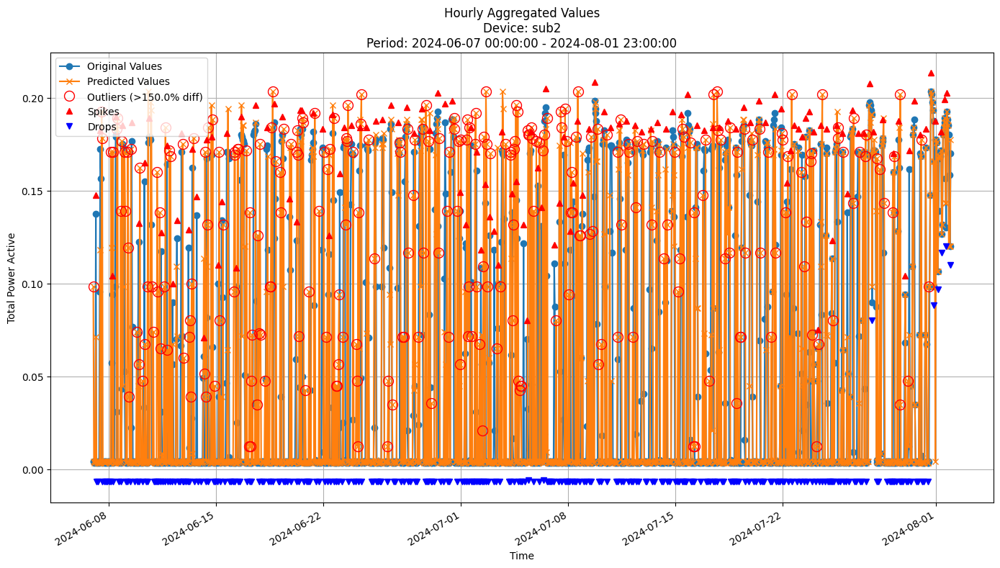


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0801
MAE: 0.0466
MAPE: 636.0808%

Directional Metrics:
Directional Accuracy: 49.5905%
First-Diff Correlation: 0.0505

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1661
  Recall: 0.3431
  F1 Score: 0.2238
Drops:
  Precision: 0.2560
  Recall: 0.3137
  F1 Score: 0.2819

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3675
  Recall: 0.7591
  F1 Score: 0.4952
Drops:
  Precision: 0.5663
  Recall: 0.6937
  F1 Score: 0.6235


In [39]:
for device_id in fodt_all_train_preds.keys():
    y_train = fodt_all_train_preds[device_id][-1]['y_true']
    y_pred_train = fodt_all_train_preds[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

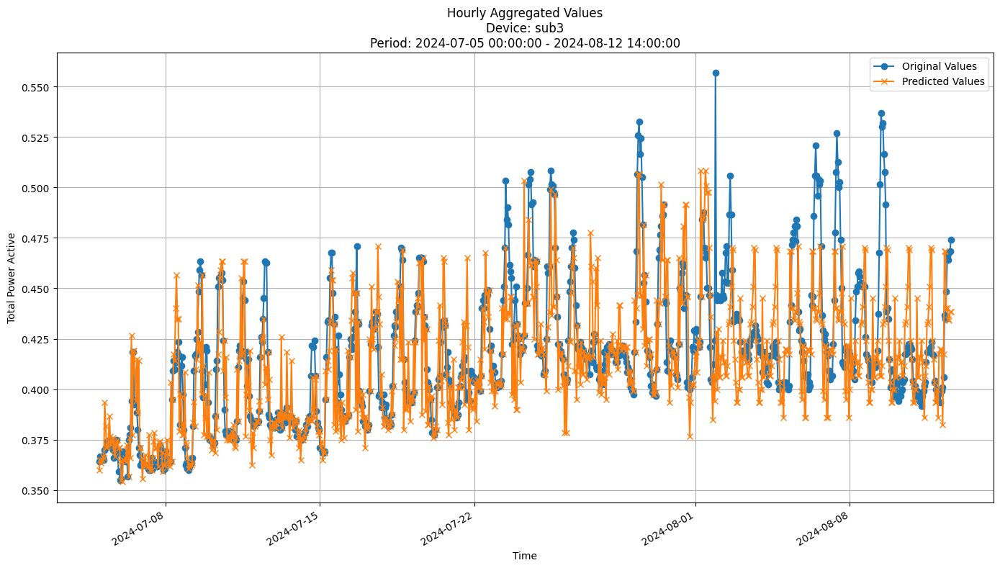


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0252
MAE: 0.0173
MAPE: 3.9732%

Directional Metrics:
Directional Accuracy: 43.7365%
First-Diff Correlation: 0.1173

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


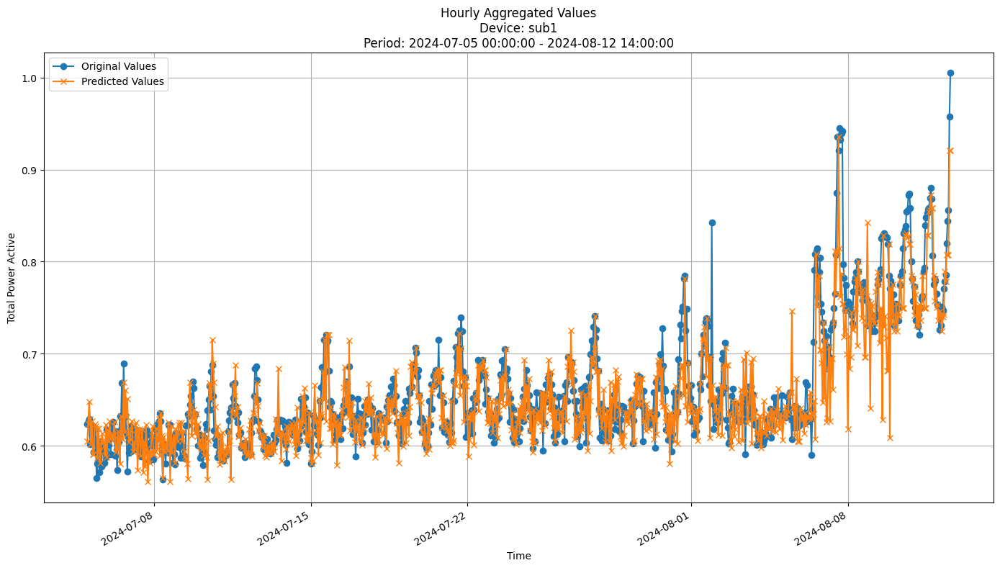


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0349
MAE: 0.0237
MAPE: 3.4747%

Directional Metrics:
Directional Accuracy: 49.8920%
First-Diff Correlation: 0.0666

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


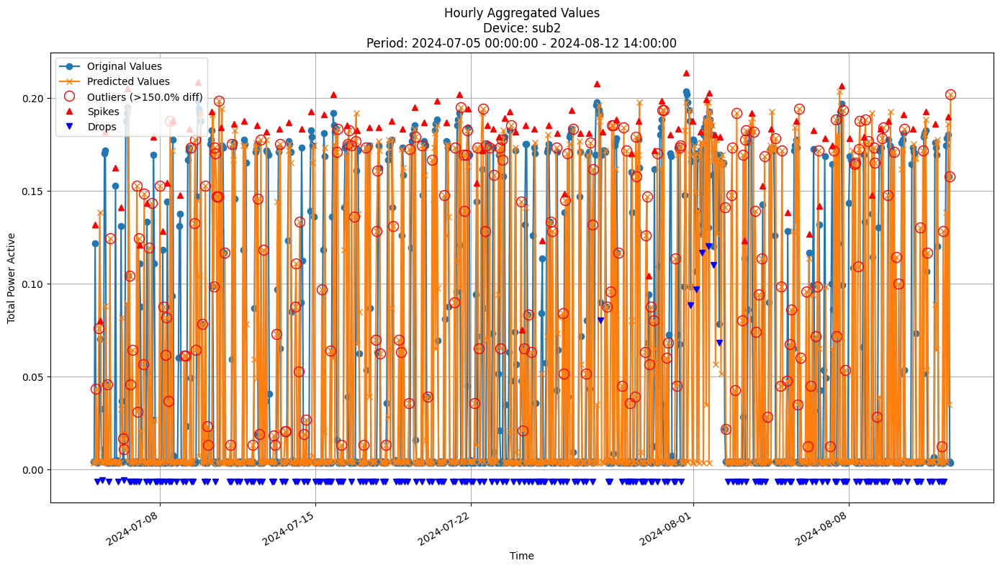


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0860
MAE: 0.0550
MAPE: 608.5642%

Directional Metrics:
Directional Accuracy: 44.9244%
First-Diff Correlation: 0.0269

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0870
  Recall: 0.2083
  F1 Score: 0.1227
Drops:
  Precision: 0.2329
  Recall: 0.3118
  F1 Score: 0.2667

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3522
  Recall: 0.8438
  F1 Score: 0.4969
Drops:
  Precision: 0.5141
  Recall: 0.6882
  F1 Score: 0.5885


In [40]:
join_periods = [-2, -1]
# Device iteration
for device_id in fodt_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, fodt_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, fodt_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (FastODT)

In [41]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

arf = ARFRegressorFODT

arf_params = {'n_models': 5, 
 'max_features': 0.5, 
 'max_depth': 30, 
 'aggregation_method': 'mean', 
 'disable_weighted_vote': True, 
#  'drift_detector': None, 
#  'warning_detector': None, 
 'eagerness': 0, 
 'tau': 0.05, 
 'delta': 0.05, 
 'grace_period': 96, 
 'grace_period_depth': 0, 
 'bin_type': 'mean', 
 'split_criterion': 'vr_rel'}

# {'depth': 30, 
#                'grace_period': 96, 
#                'grace_period_depth': 0, 
#                'split_confidence': 0.1, 
#                'max_feature': 0.7, 
#                'tie_threshold': 0.05, 
#                'bin_type': 'adaptive', 
#                'max_bins': 16, 
#                'split_criterion': 'vr_rel'}

# arf_params = {
#     "n_models": 20,
#     "aggregation_method": "mean",
#     "grace_period": 0,  # by default works for all leaves
#     "max_depth": 100,
#     "delta": 0.1,  # split confidence
#     "tau": 0.01,  # break ties
#     "seed": 42,
#     "max_features": 0.7,  # maximum feature ratio for each model
# }

In [42]:
arf_all_train_preds, arf_all_valid_preds, \
arf_all_train_metrics, arf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf,
    model_params=arf_params,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-07-04 23:00:00+02:00
Model's memory usage: 9.239815 MB
Metrics for Device: sub3 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0199
	MAE: 0.0137
	MAPE: 3.2747%

Directional Metrics:
	Directional Accuracy: 53.5022%
	First-Diff Correlation: 0.1431

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0435
		Recall: 0.0417
		F1: 0.0426
	Drops:
		Precision: 0.1739
		Recall: 0.1600
		F1: 0.1667

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.5217
		Recall: 0.5000
		F1: 0.5106
	Drops:
		Precision: 0.4783
		Recall: 0.4400
		F1: 0.4583
--------------------------------------------------
Daily

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-08-01 23:00:00+02:00
Model's memory usage: 11.836563 MB
Metrics for Device: sub3 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0180
	MAE: 0.0120
	MAPE: 2.7015%

Directional Metrics:
	Directional Accuracy: 50.3937%
	First-Diff Correlation: 0.2463

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0667
		Recall: 0.1667
		F1: 0.0952
	Drops:
		Precision: 0.1333
		Recall: 0.2857
		F1: 0.1818

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.2000
		Recall: 0.5000
		F1: 0.2857
	Drops:
		Precision: 0.3333
		Recall: 0.7143
		F1: 0.4545
--------------------------------------------------
Dail

#### Results

In [43]:
print("\n\nTrain period metrics:")
arf_all_time_train_metrics = all_time_aggregation_metrics(arf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_all_time_valid_metrics = all_time_aggregation_metrics(arf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub3
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0268 ± 0.0039
	MAE: 0.0201 ± 0.0036
	MAPE: 5.4185% ± 0.9189%

	Directional Metrics:
		Directional Accuracy: 55.4945% ± 2.6277%
		First-Diff Correlation: 0.2435 ± 0.0270

	Immediate Detection (delta=0):
		Spike Precision: 0.1037 ± 0.0296
		Spike Recall: 0.1385 ± 0.0433
		Spike F1: 0.1186 ± 0.0353
		Drop Precision: 0.1599 ± 0.0219
		Drop Recall: 0.1920 ± 0.0254
		Drop F1: 0.1745 ± 0.0235

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2500 ± 0.0833
		Spike Recall: 0.3344 ± 0.1201
		Spike F1: 0.2861 ± 0.0986
		Drop Precision: 0.3361 ± 0.0088
		Drop Recall: 0.4040 ± 0.0127
		Drop F1: 0.3669 ± 0.0105
Daily Metrics:
	RMSE: 0.5097 ± 0.1008
	MAE: 0.3911 ± 0.0741
	MAPE: 4.4781% ± 0.8077%

	Directional Metrics:
		Directional Accuracy: 80.7744% ± 4.4108%
		First-Diff Correlation: 0.6183 ± 0.1576

	Immediate Detection (delta=0):
		Spike 

#### Training plots

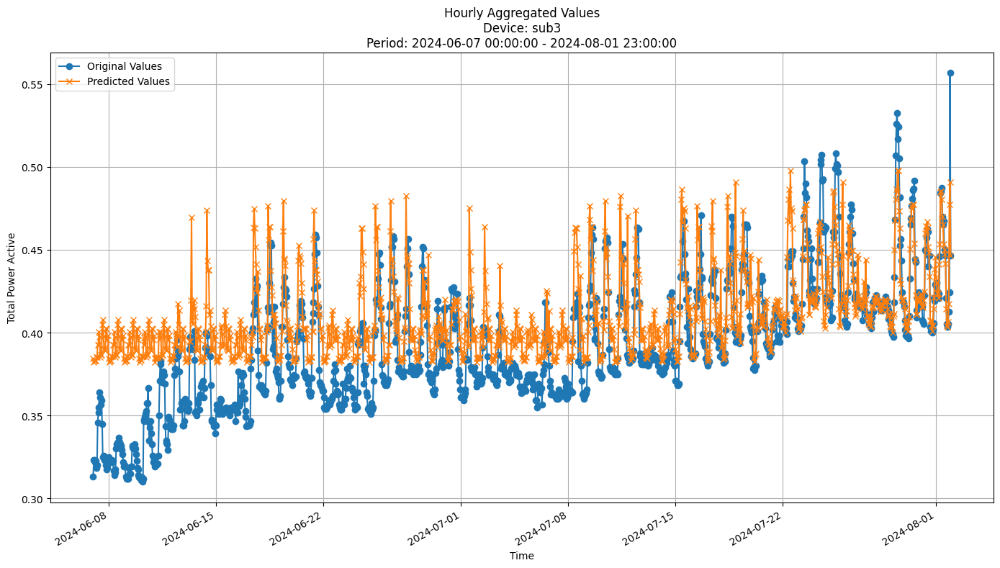


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0307
MAE: 0.0237
MAPE: 6.3375%

Directional Metrics:
Directional Accuracy: 52.8667%
First-Diff Correlation: 0.2165

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


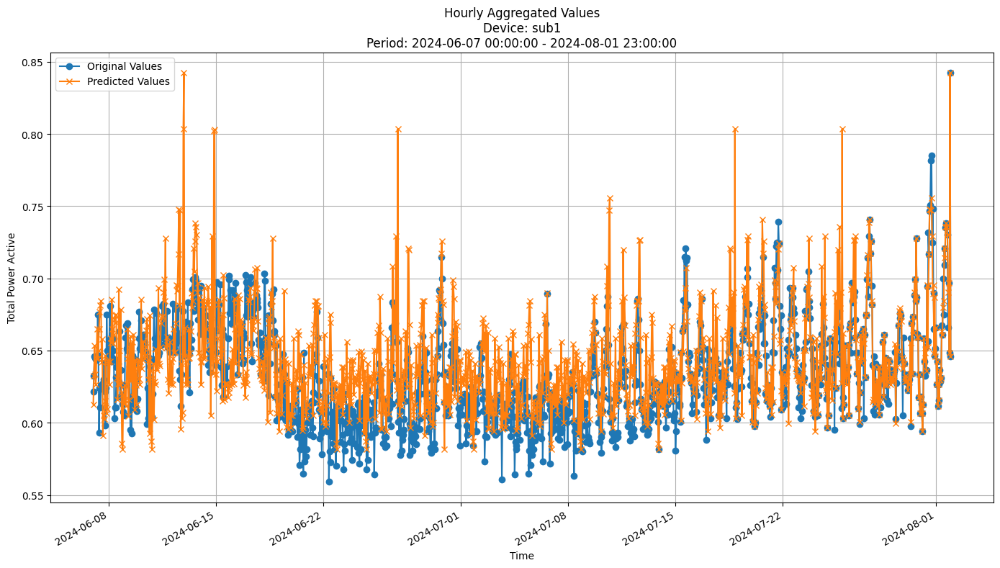


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0321
MAE: 0.0222
MAPE: 3.5568%

Directional Metrics:
Directional Accuracy: 55.1750%
First-Diff Correlation: 0.2648

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


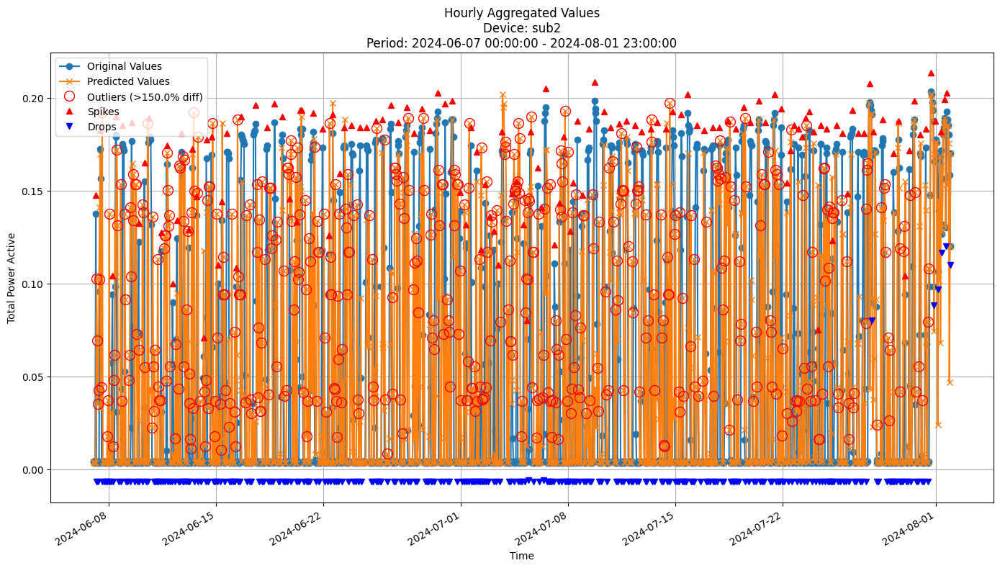


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0827
MAE: 0.0572
MAPE: 863.6666%

Directional Metrics:
Directional Accuracy: 47.2077%
First-Diff Correlation: 0.0749

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [44]:
for device_id in arf_all_train_preds.keys():
    y_train = arf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

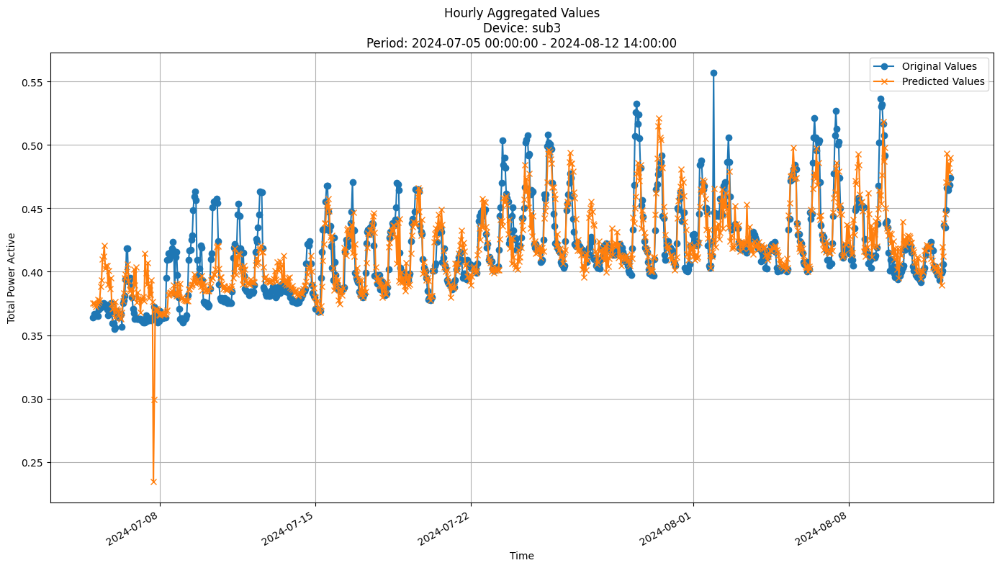


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0194
MAE: 0.0133
MAPE: 3.1170%

Directional Metrics:
Directional Accuracy: 52.6998%
First-Diff Correlation: 0.1703

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


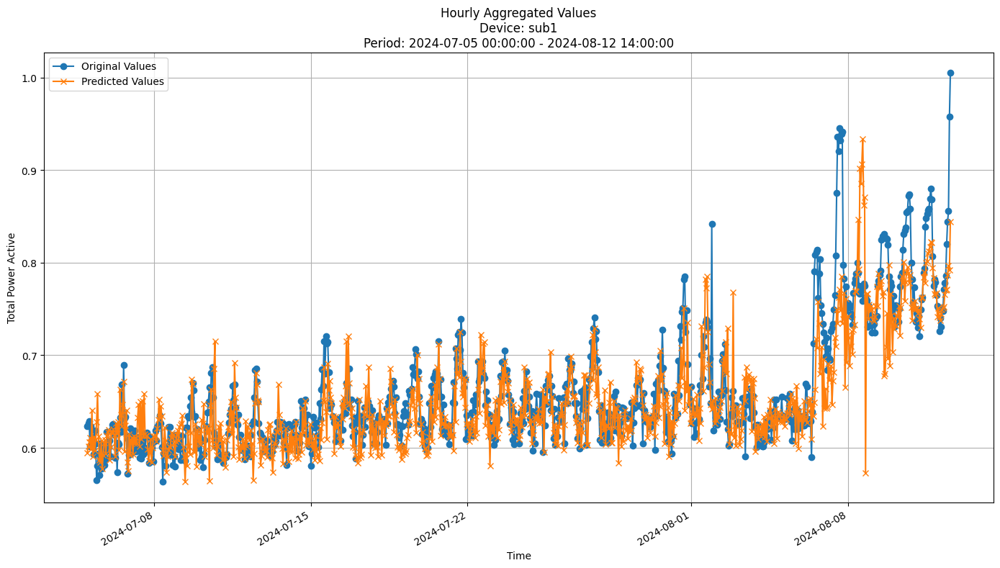


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0389
MAE: 0.0261
MAPE: 3.7851%

Directional Metrics:
Directional Accuracy: 53.5637%
First-Diff Correlation: 0.0975

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


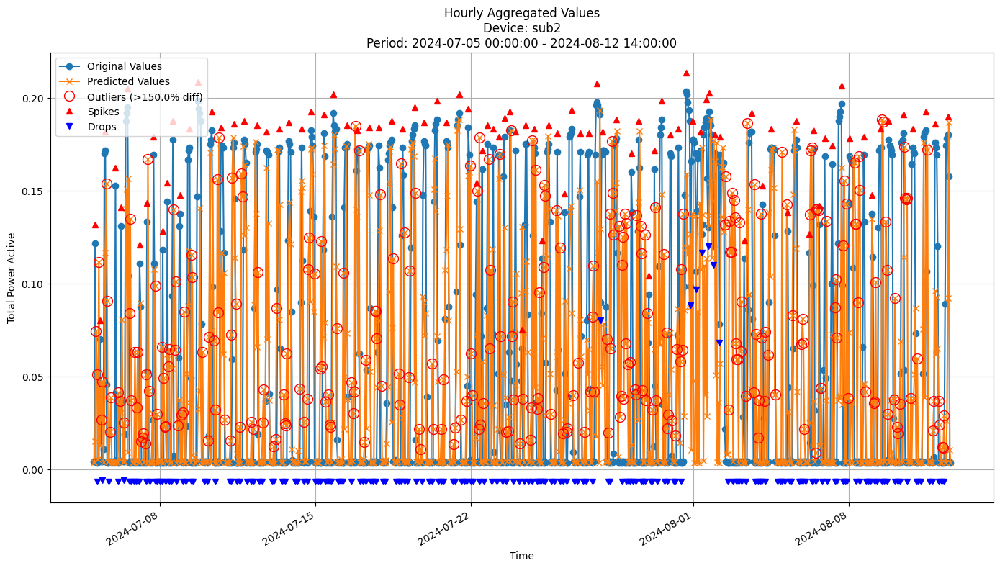


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0729
MAE: 0.0497
MAPE: 566.1947%

Directional Metrics:
Directional Accuracy: 48.4881%
First-Diff Correlation: 0.0770

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [45]:
join_periods = [-2, -1]
# Device iteration
for device_id in arf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### iNcubation Boost

In [46]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario:

incb = IncubationBoost

incb_params = {
    'base_learner': fastodt.FastODT, 
    'length': 40, 
    'learning_rate': 0.5, 
    'depth': 10, 
    'grace_period': 0, 
    'grace_period_depth': 1, 
    'split_confidence': 0.05, 
    'max_feature': 1.0, 
    'tie_threshold': 0.01, 
    'bin_type': 'adaptive', 
    'max_bins': 16, 
    'split_criterion': 'vr_rel', 
    'verbose': False}


In [47]:
incb_all_train_preds, incb_all_valid_preds, \
incb_all_train_metrics, incb_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=incb, 
    model_params=incb_params,
    train=train, 
    valid=valid, 
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    # end_split=1,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-07-04 23:00:00+02:00
Model's memory usage: 2.960602 MB
Metrics for Device: sub3 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0418
	MAE: 0.0302
	MAPE: 7.0389%

Directional Metrics:
	Directional Accuracy: 41.5797%
	First-Diff Correlation: 0.0233

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0784
		Recall: 0.1667
		F1: 0.1067
	Drops:
		Precision: 0.1000
		Recall: 0.2000
		F1: 0.1333

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.2549
		Recall: 0.5417
		F1: 0.3467
	Drops:
		Precision: 0.2000
		Recall: 0.4000
		F1: 0.2667
--------------------------------------------------
Daily

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-08-01 23:00:00+02:00
Model's memory usage: 3.619537 MB
Metrics for Device: sub3 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0361
	MAE: 0.0252
	MAPE: 5.6514%

Directional Metrics:
	Directional Accuracy: 44.4882%
	First-Diff Correlation: 0.2160

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1429
		Recall: 0.5000
		F1: 0.2222
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.2857
		Recall: 1.0000
		F1: 0.4444
	Drops:
		Precision: 0.1905
		Recall: 0.5714
		F1: 0.2857
--------------------------------------------------
Daily

#### Results

In [48]:
print("\n\nTrain period metrics:")
incb_all_time_train_metrics = all_time_aggregation_metrics(incb_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
incb_all_time_valid_metrics = all_time_aggregation_metrics(incb_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub3
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0390 ± 0.0029
	MAE: 0.0302 ± 0.0030
	MAPE: 7.9717% ± 0.7758%

	Directional Metrics:
		Directional Accuracy: 43.9852% ± 0.1281%
		First-Diff Correlation: -0.0106 ± 0.0346

	Immediate Detection (delta=0):
		Spike Precision: 0.0446 ± 0.0089
		Spike Recall: 0.1169 ± 0.0260
		Spike F1: 0.0646 ± 0.0133
		Drop Precision: 0.0897 ± 0.0004
		Drop Recall: 0.2129 ± 0.0045
		Drop F1: 0.1262 ± 0.0012

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2143 ± 0.0000
		Spike Recall: 0.5584 ± 0.0130
		Spike F1: 0.3097 ± 0.0020
		Drop Precision: 0.1974 ± 0.0188
		Drop Recall: 0.4692 ± 0.0525
		Drop F1: 0.2779 ± 0.0279
Daily Metrics:
	RMSE: 0.7134 ± 0.1046
	MAE: 0.5870 ± 0.0605
	MAPE: 6.5527% ± 0.6709%

	Directional Metrics:
		Directional Accuracy: 0.0000% ± 0.0000%
		First-Diff Correlation: nan ± nan

	Immediate Detection (delta=0):
		Spike Precis

#### Train plots

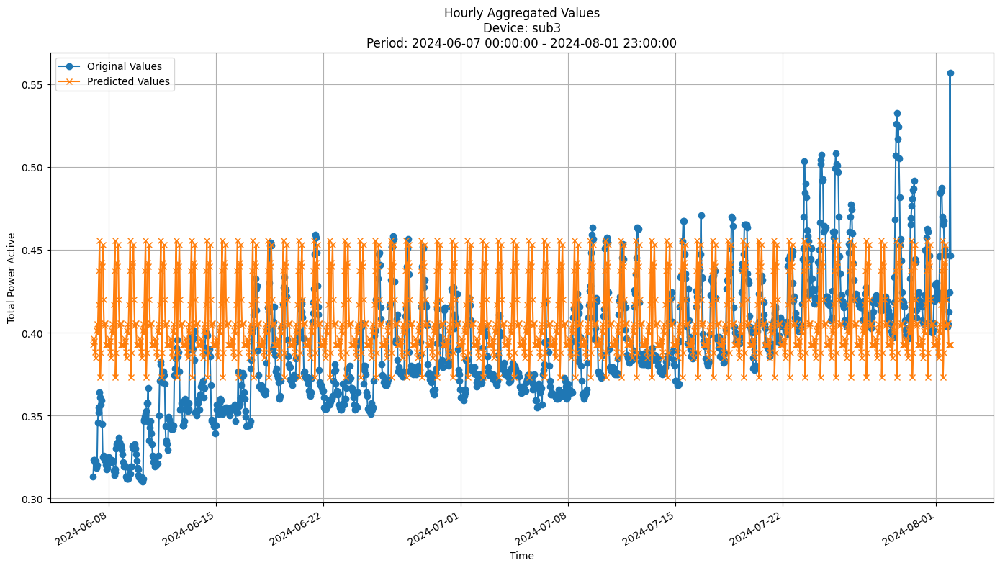


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0418
MAE: 0.0332
MAPE: 8.7475%

Directional Metrics:
Directional Accuracy: 43.8570%
First-Diff Correlation: 0.0239

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


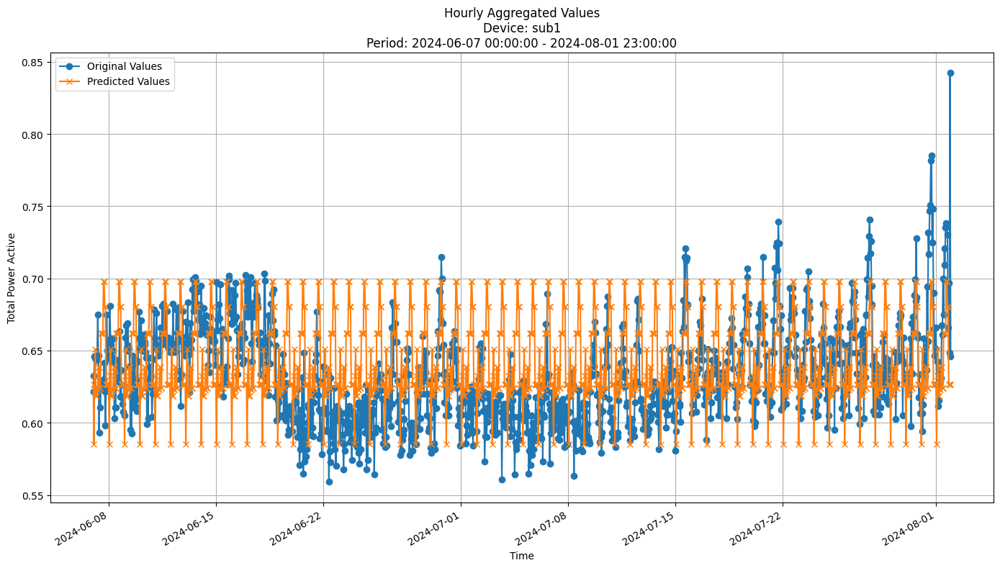


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0391
MAE: 0.0306
MAPE: 4.8756%

Directional Metrics:
Directional Accuracy: 25.6888%
First-Diff Correlation: 0.0343

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


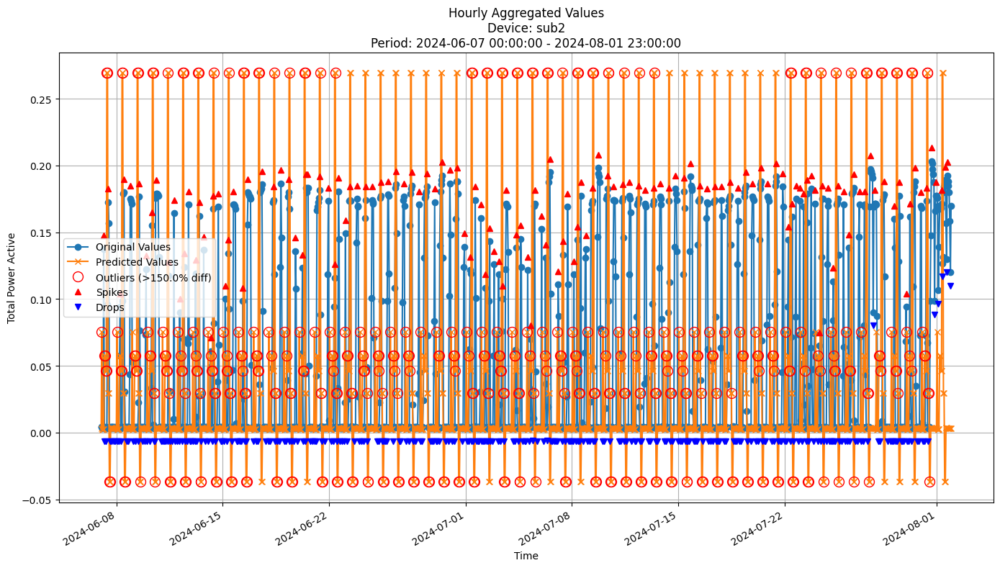


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0961
MAE: 0.0629
MAPE: 558.9683%

Directional Metrics:
Directional Accuracy: 20.9978%
First-Diff Correlation: 0.0097

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0833
  Recall: 0.1022
  F1 Score: 0.0918
Drops:
  Precision: 0.1905
  Recall: 0.1181
  F1 Score: 0.1458

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3155
  Recall: 0.3869
  F1 Score: 0.3475
Drops:
  Precision: 0.6190
  Recall: 0.3838
  F1 Score: 0.4738


In [49]:
for device_id in incb_all_train_preds.keys():
    y_train = incb_all_train_preds[device_id][-1]['y_true']
    y_pred_train = incb_all_train_preds[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

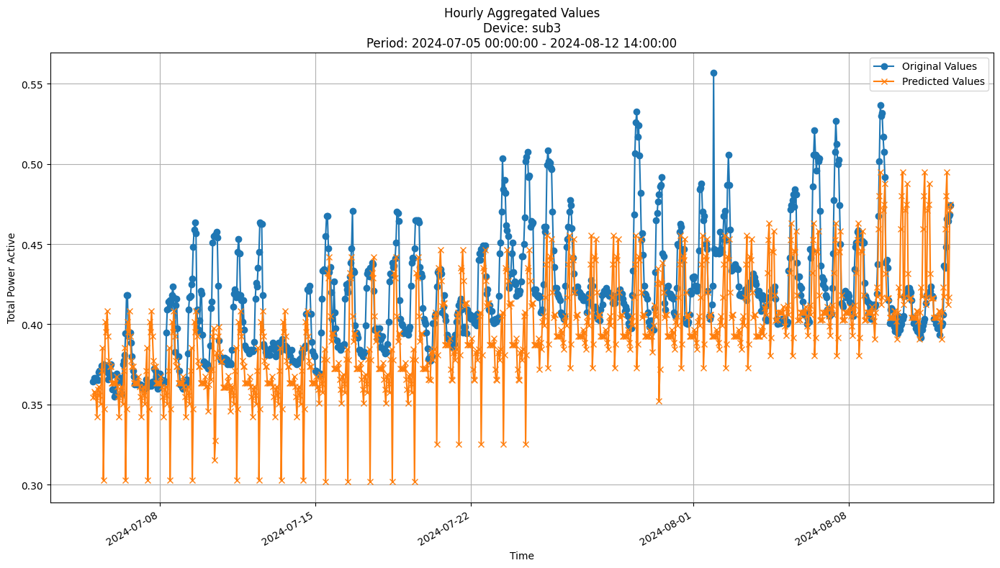


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0403
MAE: 0.0288
MAPE: 6.6573%

Directional Metrics:
Directional Accuracy: 42.3326%
First-Diff Correlation: 0.0724

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


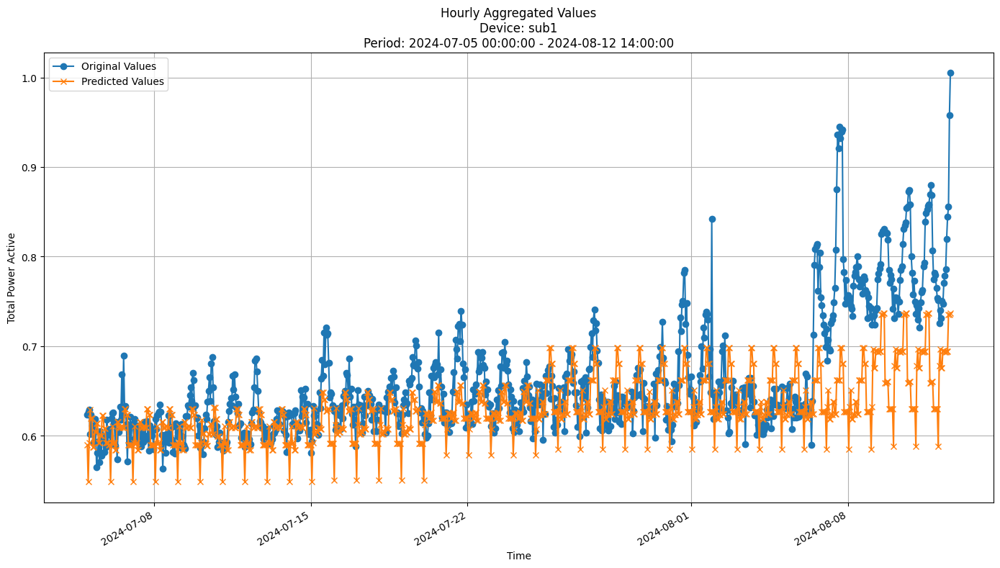


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0611
MAE: 0.0409
MAPE: 5.7520%

Directional Metrics:
Directional Accuracy: 25.5940%
First-Diff Correlation: 0.0279

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


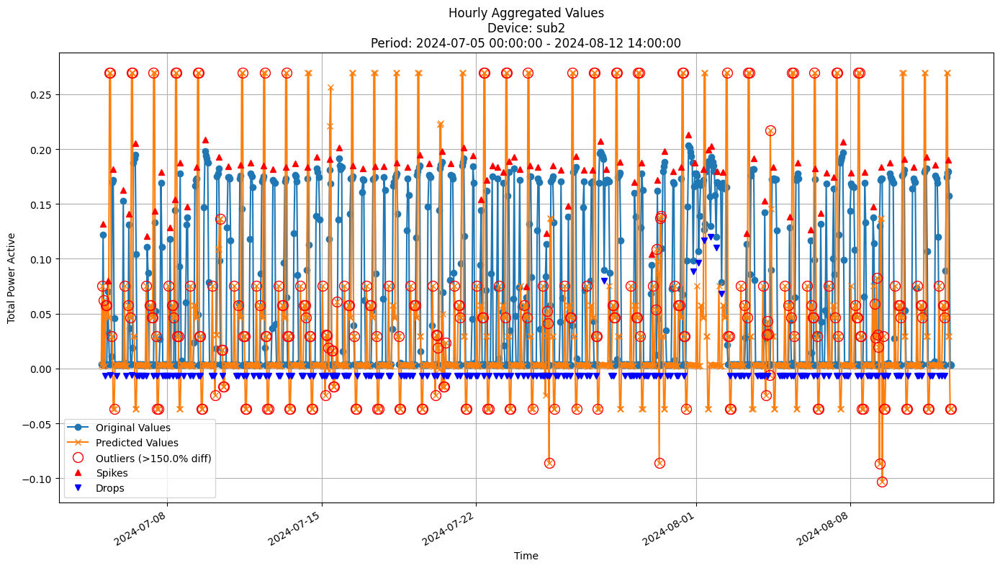


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1010
MAE: 0.0681
MAPE: 531.3634%

Directional Metrics:
Directional Accuracy: 23.0022%
First-Diff Correlation: -0.0003

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0667
  Recall: 0.0625
  F1 Score: 0.0645
Drops:
  Precision: 0.1461
  Recall: 0.0699
  F1 Score: 0.0945

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3000
  Recall: 0.2812
  F1 Score: 0.2903
Drops:
  Precision: 0.6067
  Recall: 0.2903
  F1 Score: 0.3927


In [50]:
join_periods = [-2, -1]
# Device iteration
for device_id in incb_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, incb_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, incb_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

# Test-set Model Evaluation
(`train[-1]` + `valid[-1]`) vs `test`

In [51]:
# Define model classes and params for test-set evaluation
models_classes = [bl_prev, bl_mean, gbdt, rf, hoef, arf_hf, fodt, arf, incb]
models_params = [
    bl_prev_params,
    bl_mean_params,
    gbdt_params,
    rf_params,
    hoef_params,
    arf_hf_params,
    fodt_params,
    arf_params,
    incb_params,
 ]

model_test_results = {}
for model_class, params in zip(models_classes, models_params):
    if model_class in [gbdt, rf, bl_mean]:
        incremental = False
        update_freq = "14D"
        print(f"Model: {model_class.__name__} - update_freq: {update_freq}")
    else:
        incremental = True
        update_freq = "1h"
        print(f"Model: {model_class.__name__} - update_freq: {update_freq}")

    _, test_preds, \
    _, test_metrics = test_set_seq_fit_predict(
        model_class=model_class,
        model_params=params,
        train=train,
        valid=valid,
        test=test,
        incremental=incremental,
        data_freq=DATA_FREQUENCY,
        forecast_horizon=FORECAST_HORIZON,
        features=FEATURES,
        update_freq=update_freq,
        spike_prominence=SPIKE_PROMINENCE,
        normalize_robust=True,
        predict_train=False,
        verbose=True
    )
    model_test_results[model_class.__name__] = {
        "test_preds": test_preds,
        "test_metrics": test_metrics
    }

Model: PreviousValueRegressor - update_freq: 1h


Processing devices for test predictions:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-08-12 14:00:00+02:00
Model's memory usage: 0.000374 MB
Metrics for Device: sub3 | Period: 2024-08-12 16:00:00+02:00 - 2024-08-29 13:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0097
	MAE: 0.0062
	MAPE: 1.5277%

Directional Metrics:
	Directional Accuracy: 45.4321%
	First-Diff Correlation: 0.1988

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Daily

Processing devices for test predictions:   0%|          | 0/3 [00:00<?, ?it/s]


Retraining model on data from 2024-06-07 00:00:00+02:00 to 2024-08-12 14:00:00+02:00

Time: 0.00 seconds
Predicting for chunk from 2024-08-12 16:00:00+02:00 to 2024-08-26 16:00:00+02:00

-------------------------

Retraining model on data from 2024-06-07 00:00:00+02:00 to 2024-08-26 16:00:00+02:00

Time: 0.00 seconds
Predicting for chunk from 2024-08-26 17:00:00+02:00 to 2024-08-29 13:00:00+02:00

-------------------------
Model's memory usage: 0.024391 MB
Metrics for Device: sub3 | Period: 2024-08-12 16:00:00+02:00 - 2024-08-29 13:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0156
	MAE: 0.0121
	MAPE: 2.9464%

Directional Metrics:
	Directional Accuracy: 61.4815%
	First-Diff Correlation: 0.5593

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2500
		Recall: 0.2143
		F1: 0.2308
	Drops:
		Precision: 0.0769
		Recall: 0.0588
		F1: 0.0667

Delayed Detection (delta=1 

Processing devices for test predictions:   0%|          | 0/3 [00:00<?, ?it/s]

... (9 outputs left out)

Processing devices for test predictions:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-08-12 14:00:00+02:00
Model's memory usage: 12.302635 MB
Metrics for Device: sub3 | Period: 2024-08-12 16:00:00+02:00 - 2024-08-29 13:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0170
	MAE: 0.0118
	MAPE: 2.8809%

Directional Metrics:
	Directional Accuracy: 52.5926%
	First-Diff Correlation: 0.2185

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.3571
		Recall: 0.3571
		F1: 0.3571
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.5000
		Recall: 0.5000
		F1: 0.5000
	Drops:
		Precision: 0.2667
		Recall: 0.2353
		F1: 0.2500
--------------------------------------------------
Dail

Processing devices for test predictions:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-08-12 14:00:00+02:00
Model's memory usage: 3.384575 MB
Metrics for Device: sub3 | Period: 2024-08-12 16:00:00+02:00 - 2024-08-29 13:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0357
	MAE: 0.0279
	MAPE: 6.9368%

Directional Metrics:
	Directional Accuracy: 40.7407%
	First-Diff Correlation: 0.1676

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0909
		Recall: 0.2143
		F1: 0.1277
	Drops:
		Precision: 0.0882
		Recall: 0.1765
		F1: 0.1176

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.1818
		Recall: 0.4286
		F1: 0.2553
	Drops:
		Precision: 0.2647
		Recall: 0.5294
		F1: 0.3529
--------------------------------------------------
Daily

In [52]:
for model in models_classes:
    model_test_results[model.__name__]['test_metrics'] = all_time_aggregation_metrics(
        model_test_results[model.__name__]['test_metrics'],
        data_freq=DATA_FREQUENCY,
        verbose=False)

# Model Comparison

In [53]:
AGG_LEVEL = "hourly"
METRICS = ["rmse", "mae", "mape", "dir_accuracy", "first_diff_corr"]
PERC_METRICS = ["mape", "dir_accuracy", "first_diff_corr"]
# SPIKES_METRICS = ["spikes_immediate.precision", "spikes_immediate.recall", "spikes_immediate.f1",
#                   "spikes_delayed.precision", "spikes_delayed.recall", "spikes_delayed.f1",
#                   "drops_immediate.precision", "drops_immediate.recall", "drops_immediate.f1",
#                   "drops_delayed.precision", "drops_delayed.recall", "drops_delayed.f1"]
SPIKES_METRICS = ["spikes_immediate.f1", "spikes_delayed.f1",
                  "drops_immediate.f1", "drops_delayed.f1"]

METRICS.extend(SPIKES_METRICS)
PERC_METRICS.extend(SPIKES_METRICS)

## Test results

In [54]:
MODEL_TEST_METRICS = {
    "BL_Prev": model_test_results[bl_prev.__name__]["test_metrics"],
    "BL_Mean": model_test_results[bl_mean.__name__]["test_metrics"],
    "GBDT": model_test_results[gbdt.__name__]["test_metrics"],
    "RandomForest": model_test_results[rf.__name__]["test_metrics"],
    "HoeffdingTree": model_test_results[hoef.__name__]["test_metrics"],
    "ARF_Hoeffding": model_test_results[arf_hf.__name__]["test_metrics"],
    "FastODT": model_test_results[fodt.__name__]["test_metrics"],
    "ARF_FastODT": model_test_results[arf.__name__]["test_metrics"],
    "IncubationBoost": model_test_results[incb.__name__]["test_metrics"],
}

In [55]:
def format_metric(val, is_perc=False):
    if isinstance(val, dict) and "mean" in val and "std" in val:
        mean = val["mean"]
        std = val["std"]
        if is_perc:
            mean = mean * 100
            std = std * 100
        return f"{mean:.3f} ± {std:.3f}"
    if is_perc:
        return f"{val*100:.3f}" if val is not None else None
    return f"{val:.3f}" if val is not None else None

def display_aggregated_results(model_metrics, device_ids, agg_level):
    for device_id in device_ids:
        rows = []
        for model, mdict in model_metrics.items():
            if device_id in mdict and agg_level in mdict[device_id]:
                vals = mdict[device_id][agg_level]
                row = [model]
                for m in METRICS:
                    is_perc = (m in PERC_METRICS)
                    row.append(format_metric(vals.get(m, None), is_perc=is_perc))
                rows.append(row)
        df = pd.DataFrame(rows, columns=["Model", "RMSE", "MAE", "MAPE (%)", "Directional Accuracy (%)", "First Diff Corr (%)",
                                         "Spikes Immediate F1 (%)", "Spikes Delayed F1 (%)", "Drops Immediate F1 (%)", "Drops Delayed F1 (%)"])
        print(f"\n\nDevice: {device_id} | Aggregation: {agg_level}")
        display(df)

In [56]:
device_ids = set()
for m in MODEL_TEST_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)

print("\n\n============================Hourly Test Results============================")
display_aggregated_results(MODEL_TEST_METRICS, device_ids, AGG_LEVEL)



============================Hourly Test Results============================


Device: sub1 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.028 ± 0.000,0.017 ± 0.000,1.963 ± 0.000,65.432 ± 0.000,18.836 ± 0.000,0.000 ± 0.000,100.000 ± 0.000,0.000 ± 0.000,100.000 ± 0.000
1,BL_Mean,0.236 ± 0.000,0.225 ± 0.000,25.204 ± 0.000,53.580 ± 0.000,7.789 ± 0.000,6.897 ± 0.000,34.483 ± 0.000,0.000 ± 0.000,12.903 ± 0.000
2,GBDT,0.071 ± 0.000,0.050 ± 0.000,5.452 ± 0.000,59.012 ± 0.000,13.730 ± 0.000,12.903 ± 0.000,38.710 ± 0.000,6.061 ± 0.000,6.061 ± 0.000
3,RandomForest,0.070 ± 0.000,0.050 ± 0.000,5.391 ± 0.000,60.741 ± 0.000,15.892 ± 0.000,24.242 ± 0.000,42.424 ± 0.000,11.429 ± 0.000,11.429 ± 0.000
4,HoeffdingTree,0.163 ± 0.000,0.143 ± 0.000,15.862 ± 0.000,46.173 ± 0.000,11.051 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
5,ARF_Hoeffding,0.153 ± 0.000,0.115 ± 0.000,12.497 ± 0.000,48.148 ± 0.000,5.529 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,11.111 ± 0.000,11.111 ± 0.000
6,FastODT,0.097 ± 0.000,0.074 ± 0.000,8.333 ± 0.000,48.395 ± 0.000,15.351 ± 0.000,12.500 ± 0.000,25.000 ± 0.000,19.608 ± 0.000,35.294 ± 0.000
7,ARF_FastODT,0.061 ± 0.000,0.045 ± 0.000,5.036 ± 0.000,57.531 ± 0.000,17.220 ± 0.000,6.061 ± 0.000,12.121 ± 0.000,0.000 ± 0.000,22.857 ± 0.000
8,IncubationBoost,0.134 ± 0.000,0.098 ± 0.000,10.707 ± 0.000,29.877 ± 0.000,6.005 ± 0.000,0.000 ± 0.000,15.385 ± 0.000,0.000 ± 0.000,0.000 ± 0.000




Device: sub2 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.062 ± 0.000,0.034 ± 0.000,255.408 ± 0.000,45.185 ± 0.000,12.933 ± 0.000,0.000 ± 0.000,100.000 ± 0.000,0.000 ± 0.000,100.000 ± 0.000
1,BL_Mean,0.078 ± 0.000,0.066 ± 0.000,696.107 ± 0.000,40.988 ± 0.000,-5.558 ± 0.000,2.740 ± 0.000,19.178 ± 0.000,13.592 ± 0.000,33.010 ± 0.000
2,GBDT,0.063 ± 0.000,0.052 ± 0.000,586.755 ± 0.000,55.309 ± 0.000,21.555 ± 0.000,9.302 ± 0.000,51.163 ± 0.000,31.304 ± 0.000,57.391 ± 0.000
3,RandomForest,0.063 ± 0.000,0.050 ± 0.000,531.451 ± 0.000,54.321 ± 0.000,22.701 ± 0.000,12.048 ± 0.000,50.602 ± 0.000,33.929 ± 0.000,55.357 ± 0.000
4,HoeffdingTree,0.069 ± 0.000,0.058 ± 0.000,675.112 ± 0.000,44.691 ± 0.000,14.286 ± 0.000,0.000 ± 0.000,28.169 ± 0.000,12.000 ± 0.000,32.000 ± 0.000
5,ARF_Hoeffding,0.073 ± 0.000,0.062 ± 0.000,672.045 ± 0.000,47.901 ± 0.000,2.290 ± 0.000,7.317 ± 0.000,36.585 ± 0.000,12.613 ± 0.000,37.838 ± 0.000
6,FastODT,0.085 ± 0.000,0.054 ± 0.000,530.897 ± 0.000,47.901 ± 0.000,11.351 ± 0.000,20.979 ± 0.000,50.350 ± 0.000,26.374 ± 0.000,54.945 ± 0.000
7,ARF_FastODT,0.078 ± 0.000,0.057 ± 0.000,623.566 ± 0.000,47.654 ± 0.000,9.251 ± 0.000,17.857 ± 0.000,48.214 ± 0.000,20.979 ± 0.000,46.154 ± 0.000
8,IncubationBoost,0.107 ± 0.000,0.075 ± 0.000,530.383 ± 0.000,22.222 ± 0.000,-2.337 ± 0.000,13.462 ± 0.000,28.846 ± 0.000,9.023 ± 0.000,31.579 ± 0.000




Device: sub3 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.010 ± 0.000,0.006 ± 0.000,1.528 ± 0.000,45.432 ± 0.000,19.885 ± 0.000,0.000 ± 0.000,100.000 ± 0.000,0.000 ± 0.000,100.000 ± 0.000
1,BL_Mean,0.016 ± 0.000,0.012 ± 0.000,2.946 ± 0.000,61.481 ± 0.000,55.929 ± 0.000,23.077 ± 0.000,69.231 ± 0.000,6.667 ± 0.000,40.000 ± 0.000
2,GBDT,0.011 ± 0.000,0.008 ± 0.000,2.061 ± 0.000,55.802 ± 0.000,28.930 ± 0.000,0.000 ± 0.000,37.037 ± 0.000,26.667 ± 0.000,46.667 ± 0.000
3,RandomForest,0.012 ± 0.000,0.009 ± 0.000,2.149 ± 0.000,56.049 ± 0.000,25.536 ± 0.000,0.000 ± 0.000,34.483 ± 0.000,12.500 ± 0.000,37.500 ± 0.000
4,HoeffdingTree,0.019 ± 0.000,0.015 ± 0.000,3.805 ± 0.000,47.160 ± 0.000,26.745 ± 0.000,7.692 ± 0.000,7.692 ± 0.000,13.333 ± 0.000,20.000 ± 0.000
5,ARF_Hoeffding,0.015 ± 0.000,0.012 ± 0.000,2.895 ± 0.000,51.605 ± 0.000,48.867 ± 0.000,0.000 ± 0.000,42.857 ± 0.000,0.000 ± 0.000,12.500 ± 0.000
6,FastODT,0.020 ± 0.000,0.014 ± 0.000,3.352 ± 0.000,38.519 ± 0.000,14.572 ± 0.000,0.000 ± 0.000,29.412 ± 0.000,0.000 ± 0.000,31.579 ± 0.000
7,ARF_FastODT,0.017 ± 0.000,0.012 ± 0.000,2.881 ± 0.000,52.593 ± 0.000,21.847 ± 0.000,35.714 ± 0.000,50.000 ± 0.000,0.000 ± 0.000,25.000 ± 0.000
8,IncubationBoost,0.036 ± 0.000,0.028 ± 0.000,6.937 ± 0.000,40.741 ± 0.000,16.764 ± 0.000,12.766 ± 0.000,25.532 ± 0.000,11.765 ± 0.000,35.294 ± 0.000


## Validation results

In [57]:
MODEL_VALID_METRICS = {
    "BL_Prev": bl_prev_all_time_valid_metrics,
    "BL_Mean": bl_mean_all_time_valid_metrics,
    "GBDT": gbdt_all_time_valid_metrics,
    "RandomForest": rf_all_time_valid_metrics,
    "HoeffdingTree": hoef_all_time_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_time_valid_metrics,
    "FastODT": fodt_all_time_valid_metrics,
    "ARF_FastODT": arf_all_time_valid_metrics,
    "IncubationBoost": incb_all_time_valid_metrics,
}


device_ids = set()
for m in MODEL_VALID_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)


print("\n\n============================Hourly Validation Results============================")
display_aggregated_results(MODEL_VALID_METRICS, device_ids, AGG_LEVEL)



============================Hourly Validation Results============================


Device: sub1 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.025 ± 0.000,0.018 ± 0.001,2.626 ± 0.268,41.266 ± 9.522,-25.975 ± 29.052,0.000 ± 0.000,99.275 ± 0.725,0.000 ± 0.000,100.000 ± 0.000
1,BL_Mean,0.080 ± 0.043,0.061 ± 0.034,8.134 ± 3.980,54.310 ± 0.808,13.407 ± 5.349,5.607 ± 5.607,12.150 ± 12.150,2.857 ± 2.857,12.381 ± 12.381
2,GBDT,0.038 ± 0.015,0.026 ± 0.009,3.514 ± 0.901,57.333 ± 0.640,21.618 ± 2.703,10.169 ± 10.169,11.864 ± 11.864,5.085 ± 5.085,6.780 ± 6.780
3,RandomForest,0.042 ± 0.018,0.028 ± 0.011,3.829 ± 1.164,54.550 ± 2.976,15.273 ± 8.837,6.557 ± 6.557,8.197 ± 8.197,3.333 ± 3.333,5.000 ± 5.000
4,HoeffdingTree,0.061 ± 0.032,0.049 ± 0.026,6.666 ± 3.082,48.179 ± 6.152,9.394 ± 3.309,2.469 ± 2.469,4.938 ± 4.938,2.532 ± 2.532,10.127 ± 10.127
5,ARF_Hoeffding,0.068 ± 0.039,0.051 ± 0.030,6.838 ± 3.589,52.437 ± 0.469,7.482 ± 1.473,5.479 ± 5.479,15.839 ± 3.339,1.408 ± 1.408,5.634 ± 5.634
6,FastODT,0.039 ± 0.012,0.027 ± 0.008,3.840 ± 0.813,47.564 ± 5.044,5.411 ± 5.348,7.609 ± 7.609,33.937 ± 11.715,5.682 ± 5.682,12.500 ± 12.500
7,ARF_FastODT,0.043 ± 0.014,0.030 ± 0.008,4.160 ± 0.834,53.523 ± 0.021,10.502 ± 2.028,7.692 ± 7.692,19.780 ± 19.780,2.247 ± 2.247,8.989 ± 8.989
8,IncubationBoost,0.068 ± 0.035,0.053 ± 0.028,7.209 ± 3.238,25.612 ± 0.021,2.796 ± 0.010,6.410 ± 6.410,32.168 ± 13.986,2.597 ± 2.597,12.987 ± 12.987




Device: sub2 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.058 ± 0.002,0.031 ± 0.002,243.771 ± 15.178,41.167 ± 1.009,10.417 ± 0.178,0.000 ± 0.000,100.000 ± 0.000,0.000 ± 0.000,99.811 ± 0.189
1,BL_Mean,0.076 ± 0.000,0.059 ± 0.001,624.694 ± 82.028,47.925 ± 3.043,1.148 ± 0.194,7.498 ± 2.847,26.283 ± 3.027,14.167 ± 5.833,29.722 ± 4.722
2,GBDT,0.084 ± 0.020,0.070 ± 0.023,1256.344 ± 802.626,51.298 ± 0.117,15.190 ± 9.408,15.597 ± 2.921,48.279 ± 3.834,19.887 ± 2.065,50.398 ± 4.057
3,RandomForest,0.086 ± 0.022,0.072 ± 0.024,1245.123 ± 802.558,49.798 ± 1.767,10.100 ± 16.697,12.960 ± 1.639,39.485 ± 13.070,15.742 ± 3.547,45.605 ± 4.141
4,HoeffdingTree,0.071 ± 0.002,0.056 ± 0.004,615.854 ± 154.610,42.705 ± 2.154,8.693 ± 5.066,2.837 ± 2.837,32.717 ± 16.928,7.867 ± 1.985,28.521 ± 7.932
5,ARF_Hoeffding,0.070 ± 0.001,0.057 ± 0.003,613.666 ± 120.839,47.526 ± 2.250,7.462 ± 7.331,11.455 ± 2.945,38.894 ± 9.106,8.865 ± 0.865,31.423 ± 2.090
6,FastODT,0.087 ± 0.003,0.056 ± 0.002,651.998 ± 96.555,44.014 ± 1.888,1.069 ± 3.682,11.848 ± 0.784,47.010 ± 4.905,24.220 ± 5.173,59.706 ± 2.198
7,ARF_FastODT,0.077 ± 0.010,0.054 ± 0.009,630.089 ± 142.038,47.574 ± 1.905,4.478 ± 6.995,13.176 ± 0.158,43.511 ± 16.844,16.276 ± 3.289,54.447 ± 0.099
8,IncubationBoost,0.101 ± 0.000,0.068 ± 0.001,538.992 ± 16.959,24.558 ± 3.395,2.742 ± 5.926,13.314 ± 7.025,32.864 ± 2.356,11.656 ± 0.162,43.203 ± 0.475




Device: sub3 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.012 ± 0.001,0.007 ± 0.000,1.650 ± 0.055,50.953 ± 0.165,24.979 ± 13.119,0.000 ± 0.000,98.936 ± 1.064,0.000 ± 0.000,100.000 ± 0.000
1,BL_Mean,0.044 ± 0.001,0.039 ± 0.002,9.084 ± 0.416,61.990 ± 2.541,48.182 ± 5.065,8.333 ± 8.333,35.119 ± 6.548,6.250 ± 6.250,34.583 ± 5.417
2,GBDT,0.021 ± 0.001,0.016 ± 0.002,3.742 ± 0.581,53.188 ± 2.401,19.862 ± 2.322,11.930 ± 1.404,33.567 ± 1.988,6.667 ± 6.667,13.651 ± 4.127
3,RandomForest,0.022 ± 0.000,0.017 ± 0.001,3.911 ± 0.356,52.609 ± 5.365,18.880 ± 1.787,13.882 ± 2.118,39.647 ± 4.353,3.922 ± 3.922,24.510 ± 8.824
4,HoeffdingTree,0.034 ± 0.000,0.027 ± 0.001,6.321 ± 0.168,47.935 ± 0.096,17.472 ± 3.687,8.333 ± 8.333,18.089 ± 1.423,0.000 ± 0.000,21.978 ± 6.593
5,ARF_Hoeffding,0.034 ± 0.001,0.028 ± 0.001,6.411 ± 0.121,58.275 ± 1.188,41.421 ± 6.438,10.694 ± 1.806,26.250 ± 13.750,13.333 ± 13.333,23.660 ± 11.895
6,FastODT,0.027 ± 0.005,0.019 ± 0.005,4.425 ± 1.004,41.971 ± 3.782,7.887 ± 6.747,13.559 ± 13.559,22.034 ± 22.034,6.452 ± 6.452,14.516 ± 14.516
7,ARF_FastODT,0.019 ± 0.001,0.013 ± 0.001,2.988 ± 0.287,51.948 ± 1.554,19.475 ± 5.160,6.890 ± 2.634,39.818 ± 11.246,17.424 ± 0.758,45.644 ± 0.189
8,IncubationBoost,0.039 ± 0.003,0.028 ± 0.002,6.345 ± 0.694,43.034 ± 1.454,11.966 ± 9.634,16.444 ± 5.778,39.556 ± 4.889,6.667 ± 6.667,27.619 ± 0.952


### By-period validation results

In [59]:
MODEL_VALID_PERIOD_METRICS = {
    "BL_Prev": bl_prev_valid_period_metrics,
    "BL_Mean": bl_mean_valid_period_metrics,
    "GBDT": gbdt_valid_period_metrics,
    "RandomForest": rf_valid_period_metrics,
    "HoeffdingTree": hoef_all_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_valid_metrics,
    "FastODT": fodt_all_valid_metrics,
    "ARF_FastODT": arf_all_valid_metrics,
    "IncubationBoost": incb_all_valid_metrics,
}

def show_per_period_metric_tables(device_ids, MODEL_VALID_PERIOD_METRICS, AGG_LEVEL, metric_name, display_gain=True):
    """
    Display per-period metric tables and gain/drop tables for a given metric.
    Args:
        device_ids: List of device IDs to display metrics for.
        MODEL_VALID_PERIOD_METRICS: Dictionary containing model period metrics.
        AGG_LEVEL: Aggregation level (e.g., "hourly").
        metric_name: The name of the metric to display.
        display_gain: Whether to display gain/drop tables.
    """
    for device_id in device_ids:
        period_vals = {}
        n_periods = None
        for model, mdict in MODEL_VALID_PERIOD_METRICS.items():
                if metric_name in PERC_METRICS:
                    vals = [period[AGG_LEVEL][metric_name]*100 for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                else:
                    vals = [period[AGG_LEVEL][metric_name] for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                n_periods = len(vals)
        if not period_vals:
            continue

        df_metric = pd.DataFrame(period_vals)
        df_metric.index = [f"Period {i+1}" for i in range(n_periods)]
        df_metric['Agg. Per Period'] = df_metric.astype(float).mean(axis=1)

        metric_label = f"{metric_name.upper()} (%)" if metric_name in PERC_METRICS else metric_name.upper()
        print(f"\nDevice: {device_id} | Aggregation: {AGG_LEVEL} | {metric_label} per period")
        display(df_metric)


        if display_gain:
            # Absolute gain/drop
            abs_gain = df_metric.astype(float).diff().iloc[1:]
            abs_gain = abs_gain.applymap(lambda v: f"{v:.3f}")
            abs_gain.index = [f"{df_metric.index[i]} - {df_metric.index[i-1]}" for i in range(1, len(df_metric))]
            print(f"\nAbsolute gain/drop in {metric_label}:")
            display(abs_gain)
            # Percentage gain/drop
            # pct_gain = df_metric.astype(float).pct_change().iloc[1:] * 100
            # pct_gain = pct_gain.applymap(lambda v: f"{v:.3f}")
            # pct_gain.index = abs_gain.index
            # print(f"\nPercentage gain/drop in {metric_label} (lower is better):")
            # display(pct_gain)

#### Directional accuracy (higher is better)

In [60]:
# MAPE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="dir_accuracy",
    display_gain=True
)


Device: sub1 | Aggregation: hourly | DIR_ACCURACY (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,31.744,53.502,57.973,57.526,42.027,52.906,52.608,53.502,25.633,47.491222
Period 2,50.787,55.118,56.693,51.575,54.331,51.969,42.520,53.543,25.591,49.125222



Absolute gain/drop in DIR_ACCURACY (%):


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,19.043,1.616,-1.280,-5.951,12.304,-0.937,-10.088,0.041,-0.042,1.634



Device: sub2 | Aggregation: hourly | DIR_ACCURACY (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,42.176,50.969,51.416,51.565,44.858,49.776,45.902,49.478,21.162,45.255778
Period 2,40.157,44.882,51.181,48.031,40.551,45.276,42.126,45.669,27.953,42.869556


... (2 outputs left out)


Device: sub3 | Aggregation: hourly | DIR_ACCURACY (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,51.118,64.531,55.589,57.973,47.839,59.463,45.753,53.502,41.580,53.038667
Period 2,50.787,59.449,50.787,47.244,48.031,57.087,38.189,50.394,44.488,49.606222



Absolute gain/drop in DIR_ACCURACY (%):


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-0.331,-5.082,-4.802,-10.729,0.192,-2.376,-7.564,-3.108,2.908,-3.432


#### MAPE (lower is better)

In [61]:
# MAPE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="mape",
    display_gain=True
)


Device: sub1 | Aggregation: hourly | MAPE (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,2.894,4.154,2.613,2.665,3.584,3.248,3.027,3.327,3.970,3.275778
Period 2,2.358,12.114,4.414,4.993,9.748,10.427,4.653,4.994,10.447,7.127556



Absolute gain/drop in MAPE (%):


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-0.536,7.960,1.801,2.328,6.164,7.179,1.626,1.667,6.477,3.852



Device: sub2 | Aggregation: hourly | MAPE (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,258.949,542.667,453.718,442.565,461.244,492.827,555.443,488.051,522.033,468.610778
Period 2,228.593,706.722,2058.971,2047.682,770.464,734.505,748.553,772.127,555.951,958.174222


... (2 outputs left out)


Device: sub3 | Aggregation: hourly | MAPE (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,1.704,8.668,3.161,3.556,6.153,6.290,3.421,3.275,7.039,4.807444
Period 2,1.595,9.501,4.322,4.267,6.489,6.532,5.429,2.701,5.651,5.165222



Absolute gain/drop in MAPE (%):


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-0.109,0.833,1.161,0.711,0.336,0.242,2.008,-0.574,-1.388,0.358


#### RMSE (lower is better)

In [62]:
# RMSE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="rmse",
    display_gain=True
)


Device: sub1 | Aggregation: hourly | RMSE per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,0.025,0.036,0.024,0.024,0.030,0.029,0.026,0.029,0.033,0.028444
Period 2,0.024,0.123,0.053,0.060,0.093,0.106,0.051,0.057,0.103,0.074444



Absolute gain/drop in RMSE:


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-0.001,0.087,0.029,0.036,0.063,0.077,0.025,0.028,0.070,0.046



Device: sub2 | Aggregation: hourly | RMSE per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,0.060,0.076,0.064,0.064,0.070,0.069,0.084,0.067,0.101,0.072778
Period 2,0.056,0.075,0.104,0.107,0.073,0.071,0.090,0.088,0.101,0.085000


... (2 outputs left out)


Device: sub3 | Aggregation: hourly | RMSE per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,0.013,0.043,0.021,0.022,0.033,0.033,0.022,0.020,0.042,0.027667
Period 2,0.012,0.045,0.022,0.022,0.034,0.034,0.032,0.018,0.036,0.028333



Absolute gain/drop in RMSE:


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-0.001,0.002,0.001,0.000,0.001,0.001,0.010,-0.002,-0.006,0.001
